# PCROWDers with biclonal

<frozen importlib._bootstrap>:219: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject



============================== Pt-129 ==============================
[Pt-129] 1 cells outside 11529-11871 excluded
[Pt-129] Gaussian peaks: [11578.62 11820.5 ]


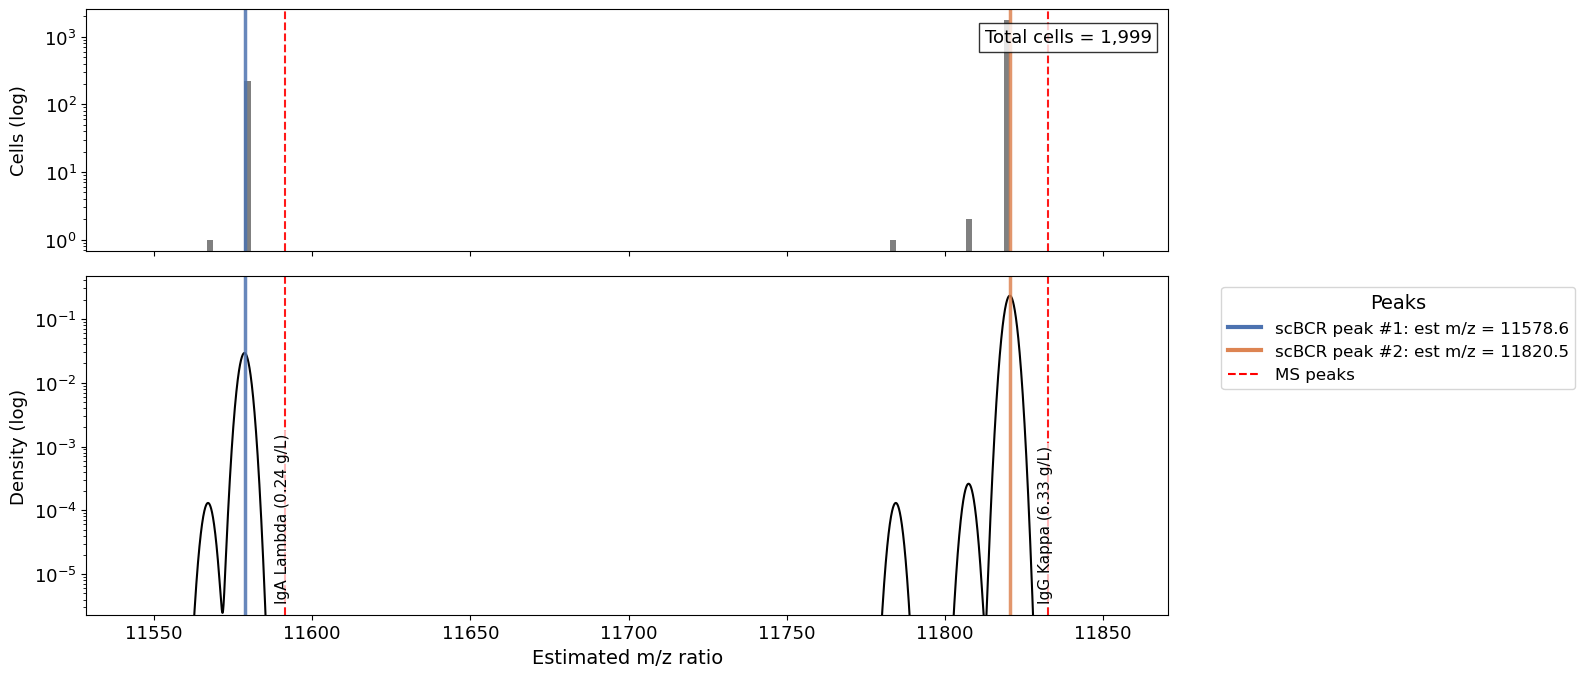

[IgA_Lambda] MS m/z=11591.3 | closest clone est_mz=11578.6 | diff=12.7 | clonality=224
[IgG_Kappa] MS m/z=11832.4 | closest clone est_mz=11820.5 | diff=11.9 | clonality=1770


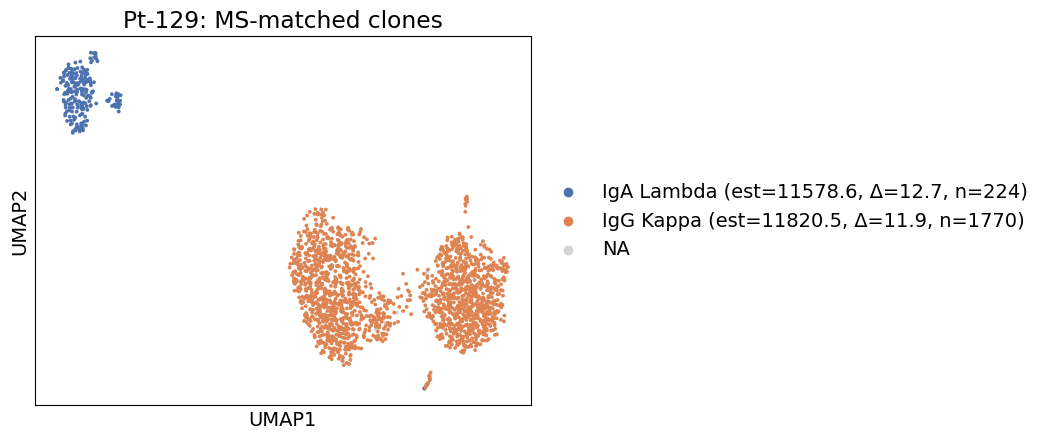

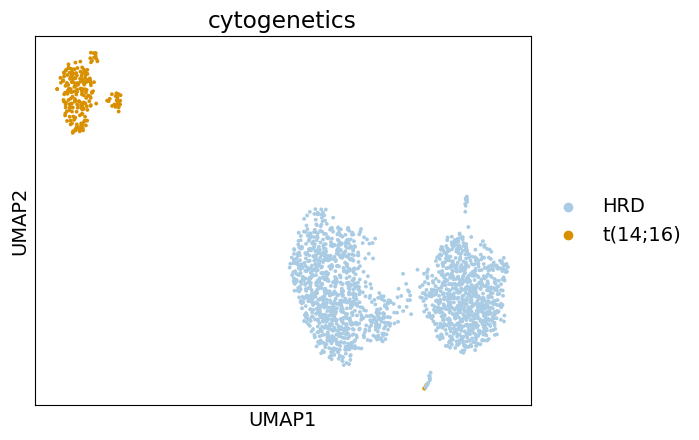

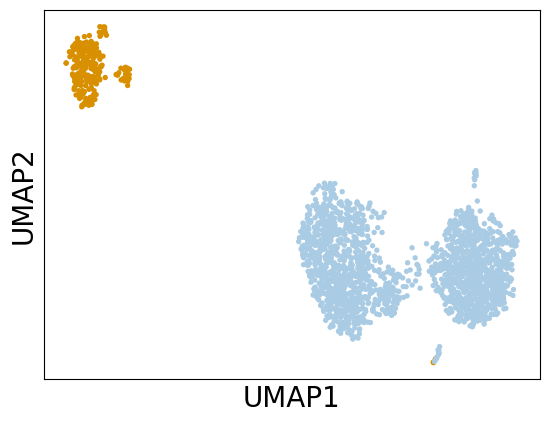


----- IgA Lambda (est=11578.6, Δ=12.7, n=224) -----
[annotation]
tumor    226 

[clone]
1    226 

[tumor_id]
Pt-129:tumor:1    226
Pt-129:tumor:0      0 

[disease_status]
LRSMM    226 

[sample_type]
PB    148
BM     78 

[cytogenetic_group]
MAF    226
HRD      0 



clone,1
annotation,
tumor,226



----- IgG Kappa (est=11820.5, Δ=11.9, n=1770) -----
[annotation]
tumor    1771 

[clone]
0    1771 

[tumor_id]
Pt-129:tumor:0    1771
Pt-129:tumor:1       0 

[disease_status]
LRSMM    1771 

[sample_type]
BM    1770
PB       1 

[cytogenetic_group]
HRD    1771
MAF       0 



clone,0
annotation,
tumor,1771



============================== Pt-155 ==============================
[Pt-155] Gaussian peaks: [11251.78 11757.54]


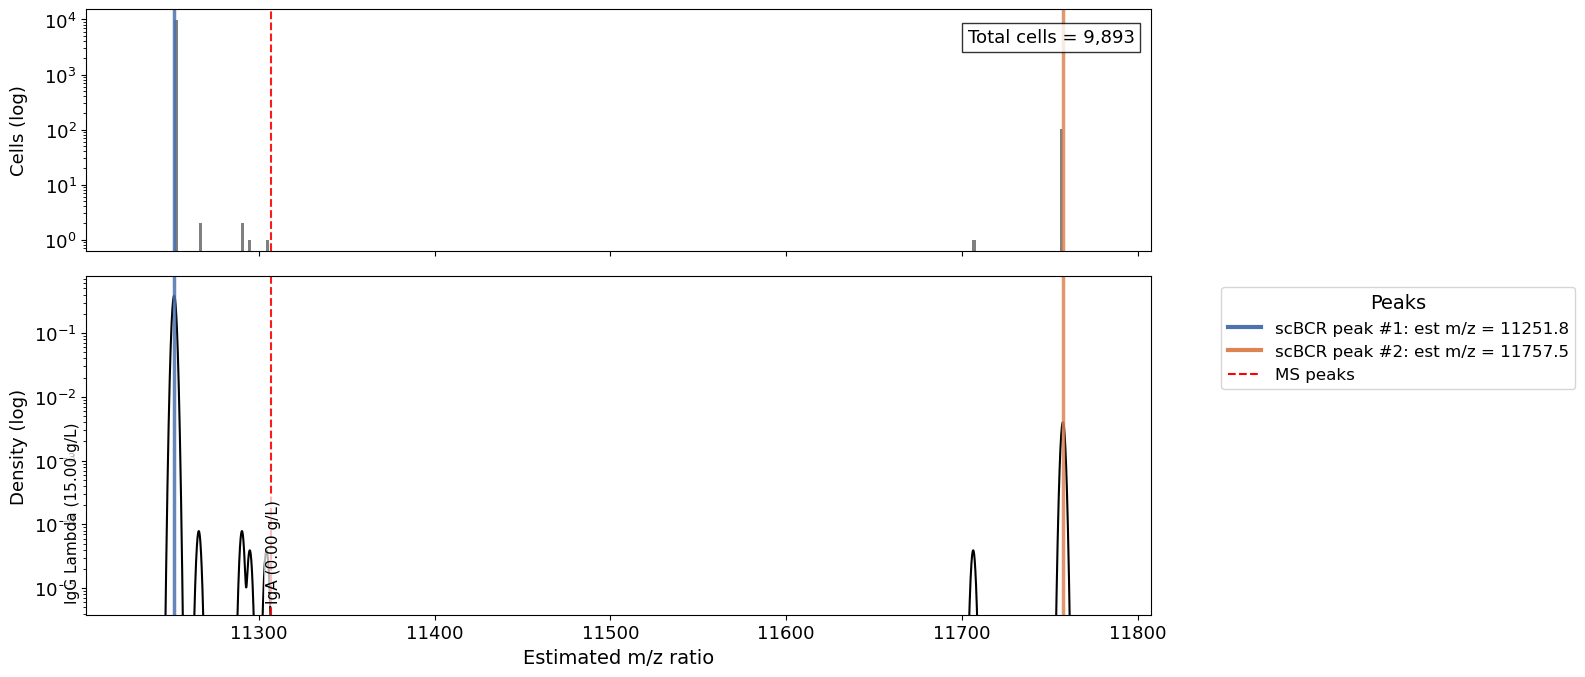

[IgA] MS m/z=11306.9 | closest clone est_mz=11757.5 | diff=450.6 | clonality=102
[IgG_Lambda] MS m/z=11192.6 | closest clone est_mz=11251.8 | diff=59.2 | clonality=9784


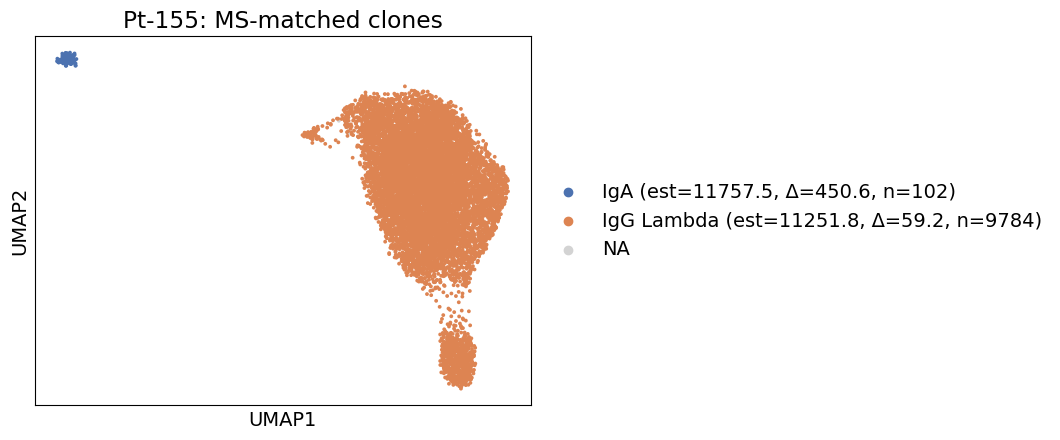

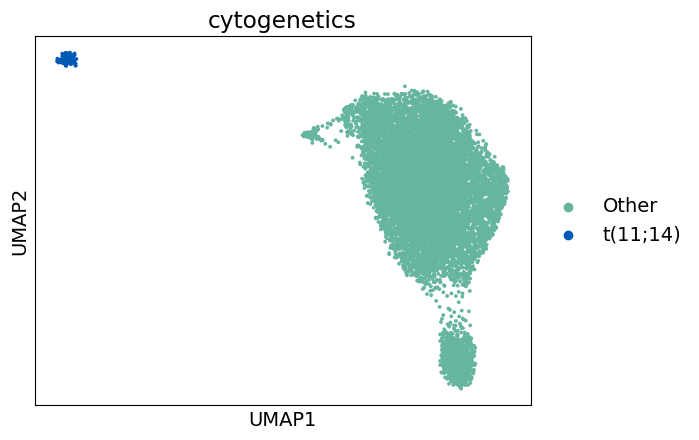

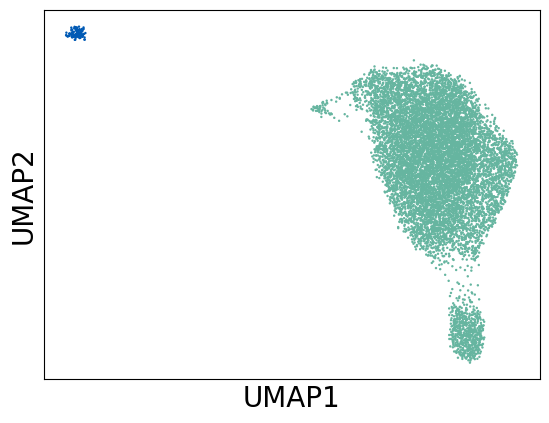


----- IgA (est=11757.5, Δ=450.6, n=102) -----
[annotation]
tumor    104 

[clone]
1    104 

[tumor_id]
Pt-155:tumor:1    104
Pt-155:tumor:0      0 

[disease_status]
LRSMM    104 

[sample_type]
BM    104
PB      0 

[cytogenetic_group]
CCND1    104
Other      0 



clone,1
annotation,
tumor,104



----- IgG Lambda (est=11251.8, Δ=59.2, n=9784) -----
[annotation]
tumor    9795 

[clone]
0    9795 

[tumor_id]
Pt-155:tumor:0    9795
Pt-155:tumor:1       0 

[disease_status]
LRSMM    9795 

[sample_type]
BM    9794
PB       1 

[cytogenetic_group]
Other    9795
CCND1       0 



clone,0
annotation,
tumor,9795



============================== Pt-185 ==============================
[Pt-185] 2 cells outside 11287-11686 excluded
[Pt-185] Gaussian peaks: [11337.03 11635.78 11649.29]


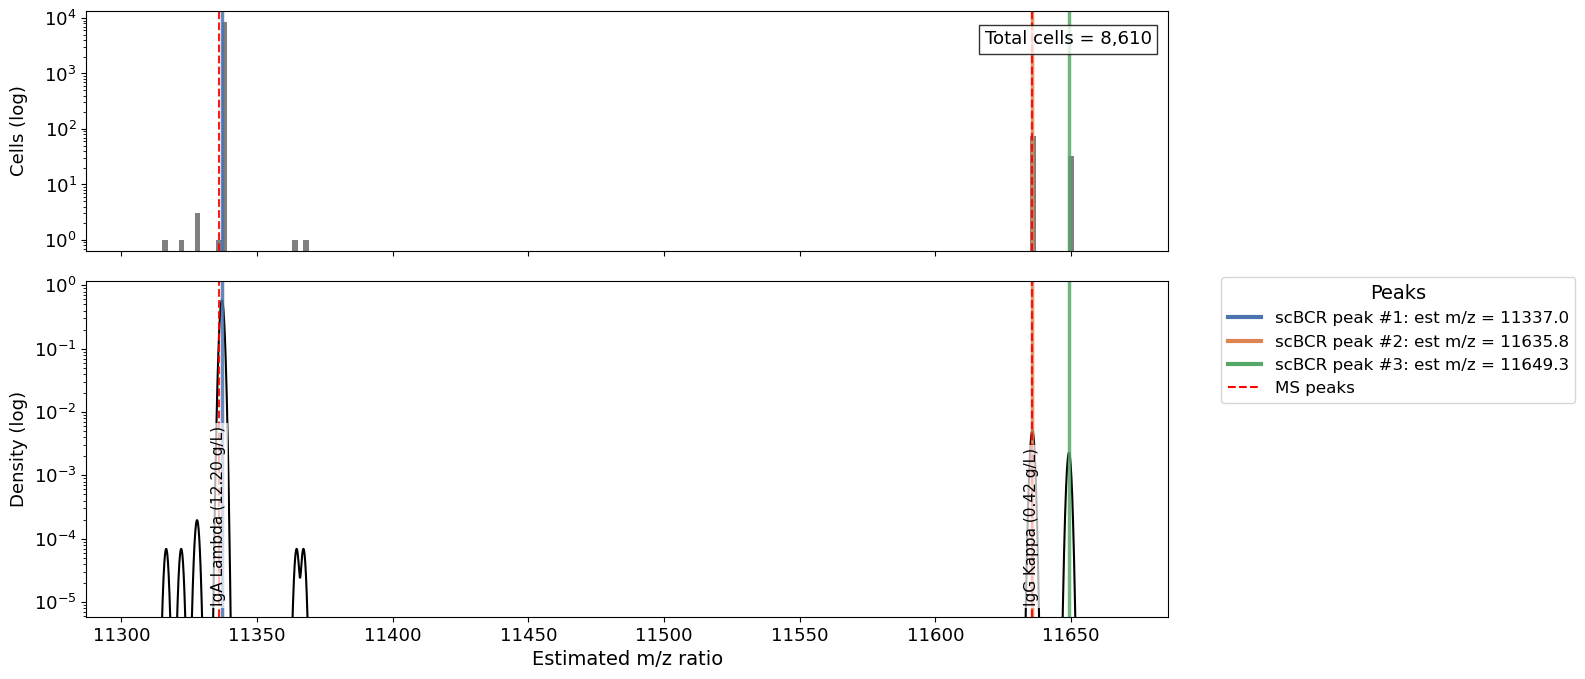

[IgA_Lambda] MS m/z=11336.1 | closest clone est_mz=11337.0 | diff=0.9 | clonality=8495
[IgG_Kappa] MS m/z=11635.8 | closest clone est_mz=11635.8 | diff=0.0 | clonality=74


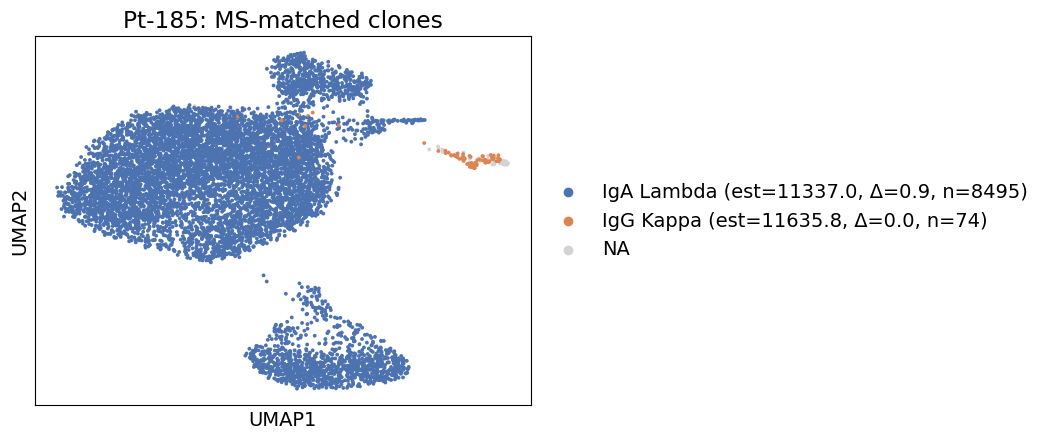

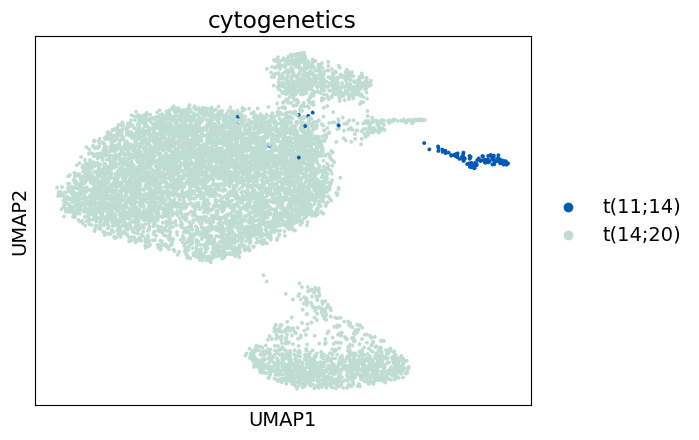

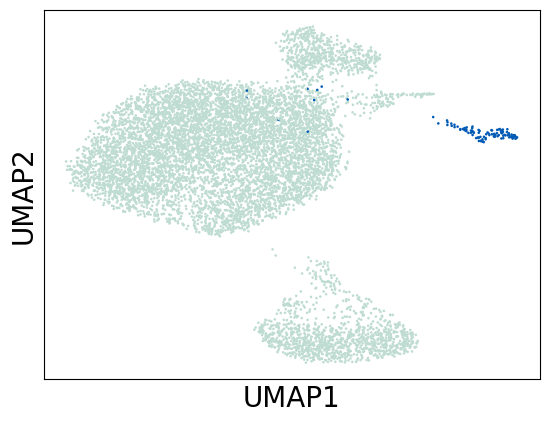


----- IgA Lambda (est=11337.0, Δ=0.9, n=8495) -----
[annotation]
tumor    8515 

[clone]
0    8515 

[tumor_id]
Pt-185:tumor:0    8515
Pt-185:tumor:1       0 

[disease_status]
LRSMM    8515 

[sample_type]
BM    8515 

[cytogenetic_group]
MAFB     8515
CCND1       0 



clone,0
annotation,
tumor,8515



----- IgG Kappa (est=11635.8, Δ=0.0, n=74) -----
[annotation]
tumor    74 

[clone]
1    73
0     1 

[tumor_id]
Pt-185:tumor:1    73
Pt-185:tumor:0     1 

[disease_status]
LRSMM    74 

[sample_type]
BM    74 

[cytogenetic_group]
CCND1    73
MAFB      1 



clone,0,1
annotation,,
tumor,1,73


In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import gseapy as gp
import scanpy.external as sce
import os, glob, re, subprocess, itertools
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore')
from peak_call_bcr import *

adata_ori = sc.read_h5ad('../data/PCROWD_biclonal.h5ad')

bcr_clone_df = pd.read_csv('../data/PCROWD_biclonal_clones.tsv', sep="\t")

patient_interest = ['Pt-129'] #, 'Pt-155'] #, 'Pt-185'] 

adata = adata_ori[adata_ori.obs['patient_id'].isin(patient_interest)].copy()

pt_map = {
    'pt1': patient_interest[0], 
    'pt2': patient_interest[1],
    'pt3': patient_interest[2],
}

cyto_palette = {
    'HRD':      '#A9CBE3',   # soft blue
    't(11;14)': '#005AB5',   # strong blue
    't(14;16)': '#D89000',   # strong amber
    't(14;20)': '#BFDCD2',   # pale mint
    'Other':    '#66B5A0',   # muted teal
}

# ---- MS results per patient (fill in the missing peak values) ----
HEAVY = {'IgM': 'IGHM', 'IgA': 'IGHA', 'IgG': 'IGHG'}
LIGHT = {'Kappa': 'IGKC', 'Lambda': 'IGLC'}

MS_result = {
    ## PANGEA_3766 | ## Seq date = 8/6/21 | MS date = 8/6/21
    patient_interest[0]: [   
        {'Type': 'IgA_Lambda', 'm_z': 11591.26002, 'Conc': 0.241},
        {'Type': 'IgG_Kappa',  'm_z': 11832.42984,      'Conc': 6.328},  
    ],
#     ## PANGEA_4626 | Seq date = 8/6/21 | MS date = 9/5/24
#     patient_interest[1]: [   
#         {'Type': 'IgA', 'm_z': 11306.9, 'Conc': 0}, 
#         {'Type': 'IgG_Lambda',  'm_z': 11192.6,      'Conc': 15},  
#     ],
#     ## PANGEA_10208 | Seq date = 10/21/22 | MS date = 10/21/22 (baseline)
#     patient_interest[2]: [   
#         {'Type': 'IgA_Lambda', 'm_z': 11336.1, 'Conc': 12.2},
#         {'Type': 'IgG_Kappa',  'm_z': 11635.8,      'Conc': 0.425},  
#     ],
}


# ---- load all est_mz_ratio BCR ----
bcr_list = []
for path in sorted(glob.glob('../data/PCROWD_biclonal_pt*_*_BCR.csv')):
    m = re.match(r'PCROWD_biclonal_(pt\d+)_(PB|BM)_BCR\.csv', os.path.basename(path))
    if m is None:
        continue
    pt_key, stype = m.groups()
    tmp = pd.read_csv(path, sep=",")
    tmp['patient_id'] = pt_map[pt_key]
    tmp['sample_type'] = stype
    tmp['barcode_pure'] = tmp['barcode'].str.split('BCR_').str[-1]
    bcr_list.append(tmp)

bcr_df = pd.concat(bcr_list, ignore_index=True)

# one row per cell (in case of duplicated barcodes within a sample)
bcr_df = bcr_df.drop_duplicates(subset=['patient_id', 'sample_type', 'barcode_pure'],
                                keep='first')

keep_cols = ['heavy_c_gene_all_contig', 'v_gene', 'j_gene', 'c_gene',
             'full_aa_seq_filt', 'heavy_cdr3_aa', 'light_cdr3_aa',
             'mz_ratio', 'clonal']

# ---- merge into adata.obs on (patient_id, sample_type, barcode) ----
obs = adata.obs.reset_index()                      # preserve original obs index
merged = obs.merge(
    bcr_df[['patient_id', 'sample_type', 'barcode_pure'] + keep_cols],
    left_on=['patient_id', 'sample_type', 'barcode'],
    right_on=['patient_id', 'sample_type', 'barcode_pure'],
    how='left',
).set_index('index')
merged = merged.loc[adata.obs.index]               # guarantee row order

for c in keep_cols:
    adata.obs[c] = merged[c].values
adata.obs['mz_ratio'] = pd.to_numeric(adata.obs['mz_ratio'], errors='coerce')
adata.obs = adata.obs.rename(columns={'mz_ratio': 'est_mz_ratio'})


obs_cols_to_check = ['annotation', 'clone', 'tumor_id', 'disease_status',
                     'sample_type', 'cytogenetic_group']
match_colors = sns.color_palette("deep", 5)

for pid in patient_interest:
    print(f"\n{'='*30} {pid} {'='*30}")
    ad = adata[adata.obs['patient_id'] == pid].copy()
    bcr = ad.obs.dropna(subset=['est_mz_ratio']).copy()
    if bcr.empty:
        print("[skip] no BCR-annotated cells"); continue
        
    # ================= est_mz_ratio spectra (histogram-calibrated) =================
    df_full = bcr[bcr['heavy_c_gene_all_contig'].notna()]
    plot_spectra_hist_kde(
      df_full['est_mz_ratio'],
      [{'mz': p['m_z'], 'label': f"{p['Type'].replace('_',' ')} ({p['Conc']:.2f} g/L)"}
       for p in MS_result.get(pid, []) if pd.notna(p['m_z']) and p['m_z'] != 0],
      pid, clip=None, kde_bw=0.02, prom_frac=0.002, min_cells=10, logy=True,
      #panel_label='Full-chain',
      save=f'../00.Figures/PCROWD_biclonal_{pid}_spectra.pdf')

    # ================= match MS peaks to closest CLONE (clonality >= 10) =================
    MIN_CLONALITY = 10
    matches = []
    for peak in MS_result.get(pid, []):
        if pd.isna(peak['m_z']) or peak['m_z'] == 0:
            continue
        parts = peak['Type'].split('_')
        hc = HEAVY.get(parts[0])
        lc = LIGHT.get(parts[1]) if len(parts) > 1 else None

        cand = bcr[bcr['heavy_c_gene_all_contig'].str.contains(hc, na=False)]
        if lc:
            cand = cand[cand['c_gene'].str.contains(lc, na=False)]
        if cand.empty:
            print(f"[{peak['Type']}] no {hc}/{lc} BCR cells"); continue

        # clone = identical full_aa_seq_filt; keep clones with >= MIN_CLONALITY cells
        clone_tbl = (cand.groupby('full_aa_seq_filt')
                         .agg(n_cells=('full_aa_seq_filt', 'size'),
                              est_mz=('est_mz_ratio', 'first')))
        clone_tbl = clone_tbl[clone_tbl['n_cells'] >= MIN_CLONALITY]
        if clone_tbl.empty:
            print(f"[{peak['Type']}] no clone with >= {MIN_CLONALITY} cells"); continue

        diffs = (clone_tbl['est_mz'] - peak['m_z']).abs()
        best_seq = diffs.idxmin()
        matches.append({'Type': peak['Type'], 'ms_mz': peak['m_z'],
                        'est_mz': float(clone_tbl.loc[best_seq, 'est_mz']),
                        'diff': float(diffs[best_seq]),
                        'n_cells': int(clone_tbl.loc[best_seq, 'n_cells']),
                        'seq': best_seq})
        print(f"[{peak['Type']}] MS m/z={peak['m_z']:.1f} | "
              f"closest clone est_mz={clone_tbl.loc[best_seq, 'est_mz']:.1f} "
              f"| diff={diffs[best_seq]:.1f} | clonality={clone_tbl.loc[best_seq, 'n_cells']}")
        
        
#     # ---- sequence-level offset diagnosis for matched clones ----
#     print("\n------ Offset diagnosis ------")
#     for m in matches:
#         sub = bcr[bcr['est_mz_ratio'] == m['est_mz']]
#         seq = str(sub['full_aa_seq_filt'].iloc[0])
#         vg  = str(sub['v_gene'].iloc[0]) if 'v_gene' in sub.columns else 'NA'
#         cg  = str(sub['c_gene'].iloc[0]) if 'c_gene' in sub.columns else 'NA'

#         # expected offset (est - MS) if this csv is from the UNCORRECTED pipeline
#         exp, notes = -1.007, []
#         if seq.startswith('Q'):
#             exp += 17.027 / 2; notes.append('pyroGlu(Q)')
#         if vg.startswith('IGLV3') and seq.startswith('S'):
#             exp += 87.078 / 2; notes.append('IGLV3 extra Ser')

#         obs = m['est_mz'] - m['ms_mz']
#         print(f"[{m['Type']}] observed={obs:+.2f} | expected={exp:+.2f} "
#               f"[{', '.join(notes) or 'no modification'}] | residual={obs-exp:+.2f}")
#         print(f"  v_gene={vg} | c_gene={cg} | N-term={seq[0]} | n_cells={m['n_cells']}")
#         print(f"  seq: {seq}")
        

    # ================= UMAP with matched clones highlighted =================
    ad.obs['ms_match'] = 'Others'
    palette = {'Others': 'lightgrey'}
    for k, m in enumerate(matches):
        lbl = (f"{m['Type'].replace('_', ' ')} "
               f"(est={m['est_mz']:.1f}, \u0394={m['diff']:.1f}, n={m['n_cells']})")
        m['label'] = lbl
        ad.obs.loc[ad.obs['est_mz_ratio'] == m['est_mz'], 'ms_match'] = lbl
        palette[lbl] = match_colors[k % len(match_colors)]

    ad_u = ad.copy()

    # start from raw counts if available (X may already be processed)
    if 'counts' in ad_u.layers:
        ad_u.X = ad_u.layers['counts'].copy()
    elif ad_u.raw is not None:
        ad_u = ad_u.raw.to_adata()
        ad_u.obs = ad.obs.copy()

    # mask IG / MT / ribosomal genes so clustering isn't driven by the BCR itself
    mask = (ad_u.var_names.str.startswith('MT-')
            | ad_u.var_names.str.startswith('RPL')
            | ad_u.var_names.str.startswith('RPS'))
    ad_u = ad_u[:, ~mask].copy()

    ## Normalize and log
    sc.pp.normalize_total(ad_u, target_sum=1e4)
    sc.pp.log1p(ad_u)
    sc.pp.highly_variable_genes(ad_u, n_top_genes=2000)
    ad_u.raw = ad_u
    ad_u = ad_u[:, ad_u.var['highly_variable']].copy()
    sc.pp.scale(ad_u, max_value=10)

    sc.tl.pca(ad_u, n_comps=30)
    sc.pp.neighbors(ad_u, n_neighbors=15)
    sc.tl.umap(ad_u)

    ad_u.obs['ms_match'] = ad.obs['ms_match'].values

    sc.pl.umap(ad_u, color='ms_match', palette=palette, size=30,
               groups=[m['label'] for m in matches],
               title=f"{pid}: MS-matched clones",
               #save=f'../00.Figures/PCROWD_biclonal_{pid}_ms_match.pdf'
              )
    
    sc.pl.umap(ad_u, color='cytogenetics', palette=cyto_palette, size=30,
               #save=f'../00.Figures/PCROWD_biclonal_{pid}_ms_match.pdf'
              )
    
    ### Figure (cytogenetics)
    plt.rcParams.update({'font.size': 20})
    fig, ax = plt.subplots()
    sc.pl.embedding(ad_u, basis='X_umap', 
            color = ['cytogenetics'],
            palette=cyto_palette,
            title='', legend_loc='none',
            ax=ax, show=False
    ) 
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    fig.savefig(f'../00.Figures/PCROWD_biclonal_{pid}_annotation.pdf', format='pdf', bbox_inches='tight')
    plt.show()

    # ================= 3c) are the matched cells tumor? =================
    for m in matches:
        sub = ad.obs[ad.obs['ms_match'] == m['label']]
        print(f"\n----- {m['label']} -----")
        for col in obs_cols_to_check:
            if col in sub.columns:
                print(f"[{col}]")
                print(sub[col].value_counts(dropna=False).to_string(), "\n")
        if {'annotation', 'clone'} <= set(sub.columns):
            display(pd.crosstab(sub['annotation'], sub['clone']))
            
            


# MM subclone case

## MS spectra 

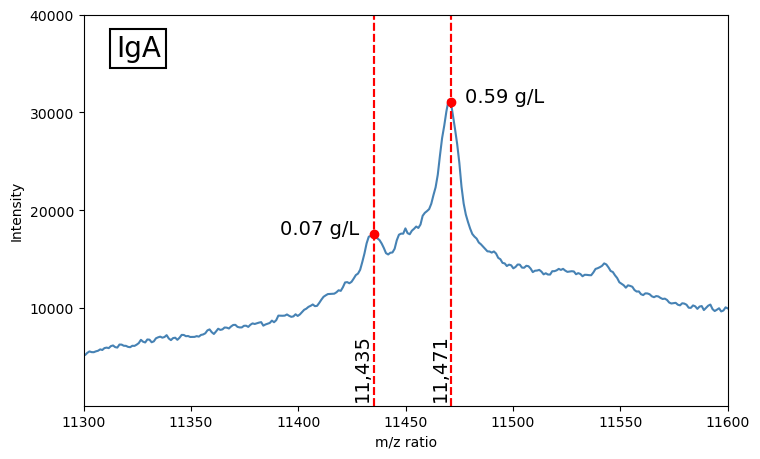

In [3]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load('../data/22051100_MSXXXX794.npy') ## Raw, not re-calibrated data
labels = ["G", "A", "M", "K", "L"]

fig, ax = plt.subplots(figsize=(8, 5)) 
plt.rcParams.update({'font.size': 20})

i = 1  
mz = data[0, i, :].astype(float) + 3.5 ## manually recalibrate
intensity = data[1, i, :].astype(float)

ax.plot(mz, intensity, color='steelblue')
ax.set_ylabel('Intensity')
ax.set_xlabel("m/z ratio")
ax.set_ylim(bottom=0)

# Red vertical lines at specific m/z
for xline in [11435, 11471]:
    ax.axvline(x=xline, color='red', linestyle='--', linewidth=1.5)

# Optional: Customize x-axis range
ax.set_xlim(11300, 11600)  

highlight_mz = [11435, 11471]
highlight_vals = [0.068, 0.586]

for j, (m, y_text) in enumerate(zip(highlight_mz, highlight_vals)):
    ax.axvline(x=m, color='red', linestyle='--', linewidth=1.5)
    y_offset = 17550 + j * 13500  # 15000, 25000 ...
    ax.plot(m, y_offset, 'o', color='red')
    if j == 0:
        ax.text(m-25, y_offset, f"{y_text:.2f} g/L", color='black', fontsize=14, ha='center')
    else:
        ax.text(m+25, y_offset, f"{y_text:.2f} g/L", color='black', fontsize=14, ha='center')
    ax.text(m-5, 500, f"{int(m):,}", color='black', fontsize=14,
            ha='center', va='bottom', rotation=90)

ax.text(
    0.05, 0.95, "IgA",
    transform=ax.transAxes,
    fontsize=20,
    #fontweight='bold',
    ha='left',
    va='top',
    bbox=dict(facecolor='none', edgecolor='black',  linewidth=1.5)
) 

yticks = ax.get_yticks()
yticks_no_zero = [tick for tick in yticks if tick != 0]
ax.set_yticks(yticks_no_zero)

plt.tight_layout()
plt.savefig(f'../00.Figures/PCROWD_MM_MassSpect_spectra_IgA.pdf', format='pdf', bbox_inches='tight')
plt.show()


## Reconstruct MS spectra

<frozen importlib._bootstrap>:219: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


[PCROWD_MM_full] 842 cells outside 11420-11500 excluded
[PCROWD_MM_full] Gaussian peaks: [11435.1  11471.14]


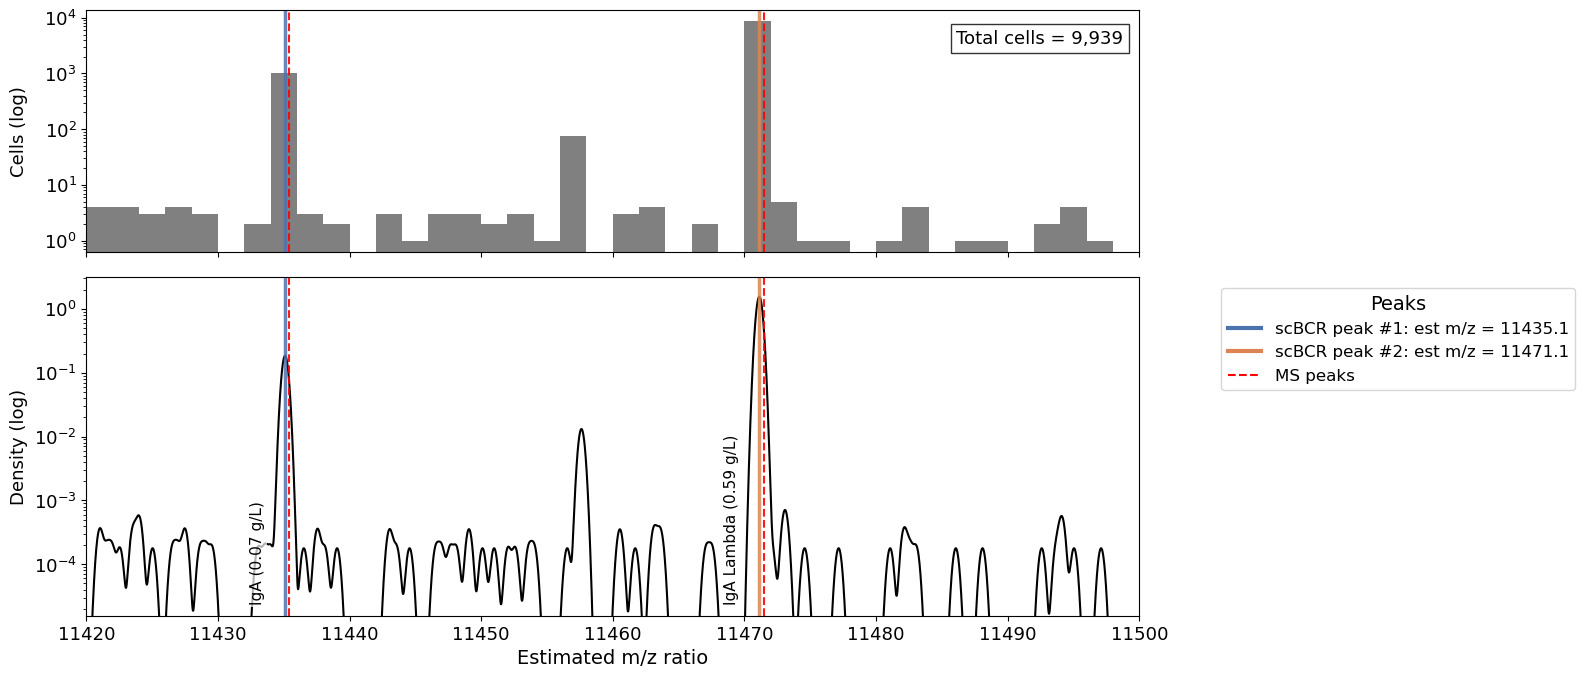

[PCROWD_MM_light] 38 cells outside 11420-11500 excluded
[PCROWD_MM_light] Gaussian peaks: [11435.1  11457.62 11471.14]


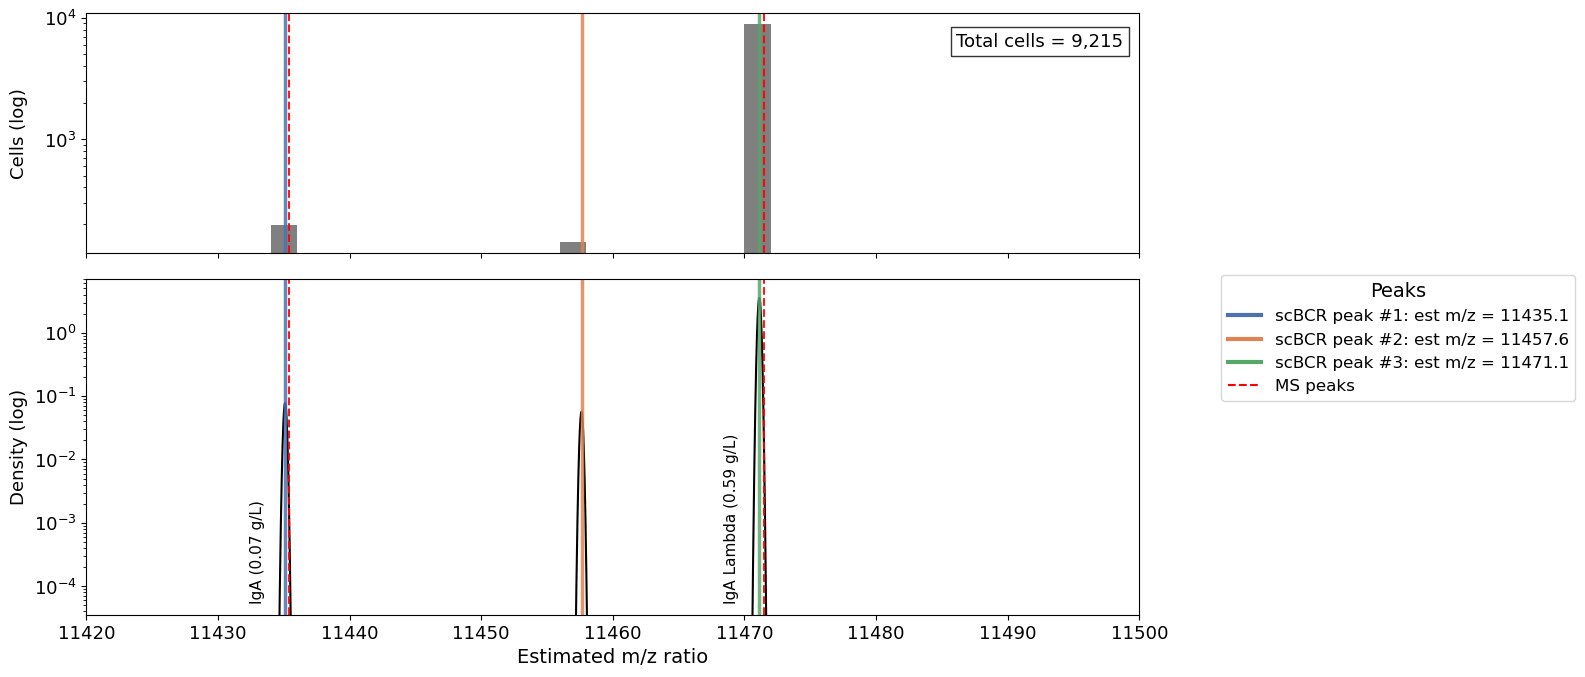

array([11435.10188774, 11457.62470309, 11471.13639205])

In [1]:
import pandas as pd
import numpy as np
import os, glob, subprocess, itertools
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import colorcet as cc
import matplotlib.cm as cm
import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import KMeans
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks
from peak_call_bcr import *

ms_results = [
    'IGHA_IGLC:11471.47127:0.586:2:Plasma:nan:nan:nan',
    'IGHA:11435.401:0.068:2:Plasma:nan:nan:nan',
]

input_df = pd.read_csv('../data/PCROWD_MM_BCR.csv', sep=",")
ms_list = parse_ms_results(ms_results)

df_full  = input_df[input_df['heavy_c_gene_all_contig'].notna()]
df_light = input_df[input_df['heavy_c_gene_all_contig'].isna()]

plot_spectra_hist_kde(df_full['mz_ratio'], ms_list, 'PCROWD_MM_full',
                      clip=(11420, 11500), kde_bw=0.02, prom_frac=0.01,
                      min_cells=10, logy=True, #panel_label='Full-chain',
                      save='../00.Figures/PCROWD_MM_recon_MS_Zoomed_full.pdf')

plot_spectra_hist_kde(df_light['mz_ratio'], ms_list, 'PCROWD_MM_light',
                      clip=(11420, 11500), kde_bw=0.02, prom_frac=0.01,
                      min_cells=10, logy=True, #panel_label='Light-chain',
                      save='../00.Figures/PCROWD_MM_recon_MS_Zoomed_light.pdf')



## Draw UMAP and downstream analyses

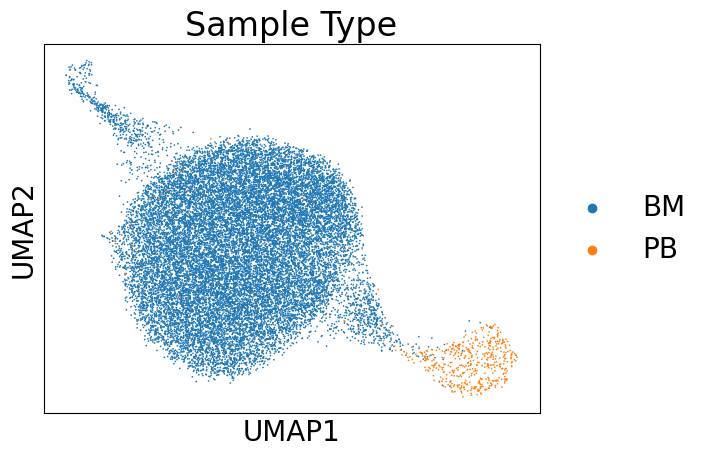

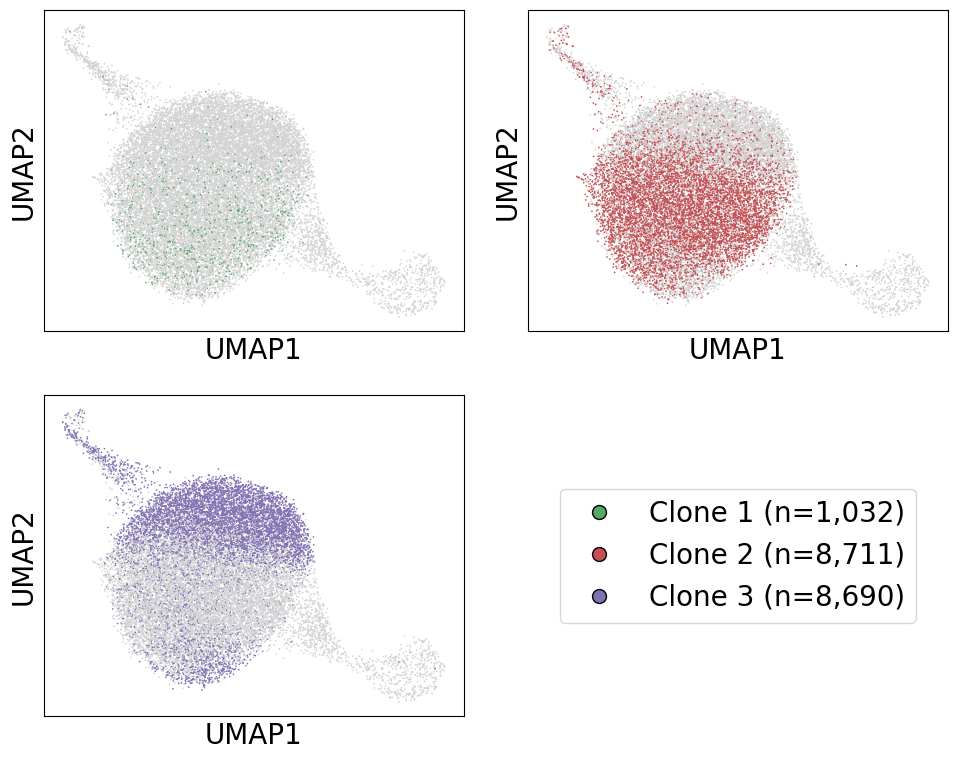

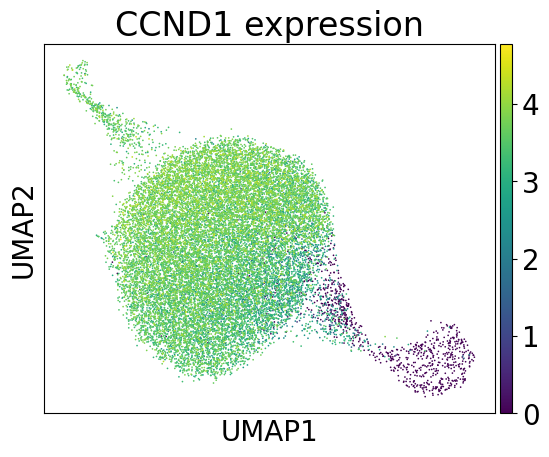

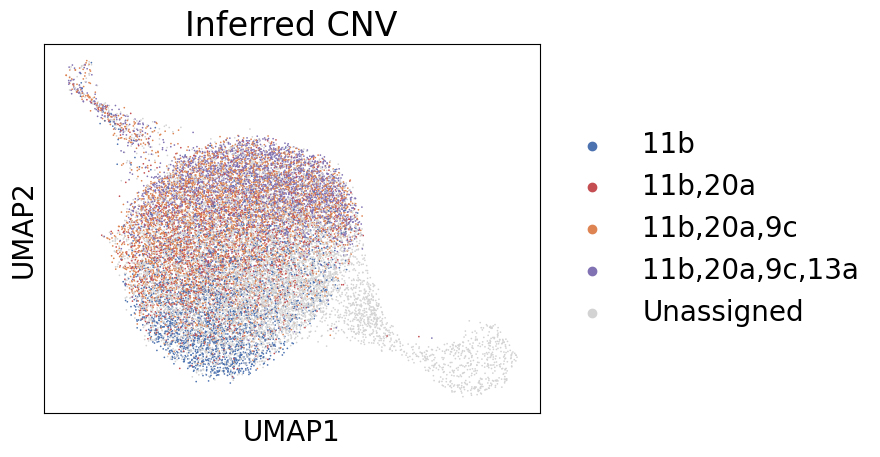

full_cdr3_top3
-                             721
-CQSWGTYVVF                  9022
CARHVGSLGPVDYW-CQSWGTYVVF    9820
NaN                           904
dtype: int64


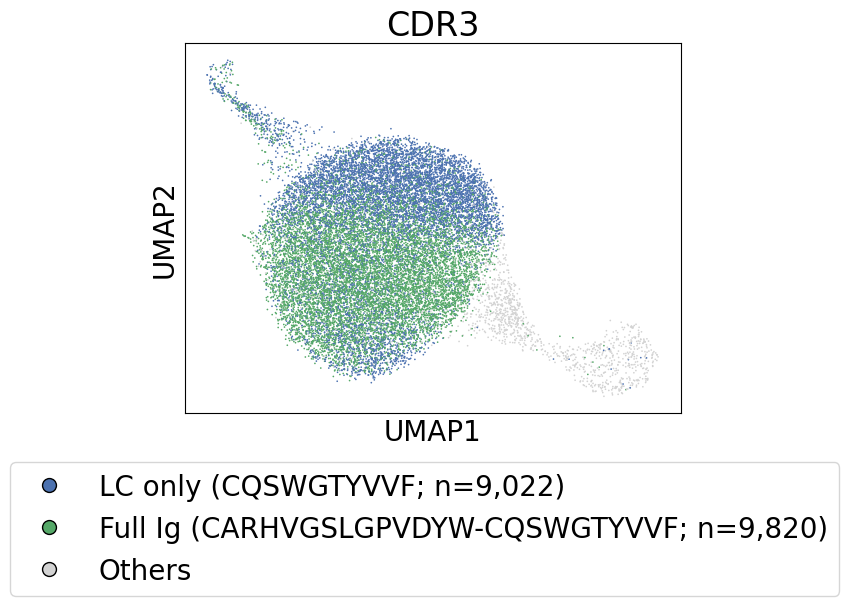

In [27]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import KMeans
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks
import numpy as np
import pandas as pd
import scanpy as sc
import gseapy as gp
import scanpy.external as sce
import os, glob, subprocess, itertools
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from statannotations.Annotator import Annotator
from scipy.stats import mannwhitneyu
from scipy.stats import pearsonr
from scipy.stats import wilcoxon
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests
from sklearn.utils import resample
from scipy.stats import permutation_test
from scipy.stats import bootstrap
from Levenshtein import distance as levenshtein_distance
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import chi2_contingency, fisher_exact
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error
import numpy as np

adata = sc.read_h5ad('../data/PCROWD_MM.h5ad')
input_df = pd.read_csv('../data/PCROWD_MM_BCR.csv', sep=",")

bcr = input_df.drop_duplicates(subset='barcode', keep='first')
dup_cols = [c for c in bcr.columns if c in adata.obs.columns and c != 'barcode']
obs = adata.obs.drop(columns=dup_cols)

obs = (obs.reset_index()
          .merge(bcr, on='barcode', how='left')
          .set_index('index'))
adata.obs = obs.loc[adata.obs.index]          


## CDR3 aa
adata.obs['full_cdr3'] = adata.obs.apply(
    lambda row: (row['heavy_cdr3_aa'] if pd.notna(row['heavy_cdr3_aa']) else '') + '-' + 
                (row['light_cdr3_aa'] if pd.notna(row['light_cdr3_aa']) else ''), 
    axis=1
)
# top3 captures LC only, full chain and HC only (top4 and 5 is small population)
top3_full_cdr3 = adata.obs['full_cdr3'].value_counts().nlargest(3).index
adata.obs['full_cdr3_top3'] = adata.obs['full_cdr3'].apply(lambda x: x if x in top3_full_cdr3 else 'NaN')

cdr3_label_map = {
    '-CQSWGTYVVF': "LC only (CQSWGTYVVF; n={:,})",
    'CARHVGSLGPVDYW-.': "Others", #"HC only (CARHVGSLGPVDYW; n={:,})",
    'CARHVGSLGPVDYW-CQSWGTYVVF': "Full Ig (CARHVGSLGPVDYW-CQSWGTYVVF; n={:,})"
}

cdr3_counts = adata.obs['full_cdr3_top3'].value_counts()

def get_human_label(cdr3):
    if cdr3 in cdr3_label_map:
        count = cdr3_counts.get(cdr3, 0)
        return cdr3_label_map[cdr3].format(count)
    else:
        return 'Others'

adata.obs['full_cdr3_top3_UMAP'] = adata.obs['full_cdr3_top3'].apply(get_human_label)


## full or light-chain only
adata.obs['heavy_light'] = np.where(
    adata.obs['heavy_cdr3_aa'].notna() & adata.obs['light_cdr3_aa'].notna(), 'full',
    np.where(adata.obs['light_cdr3_aa'].notna(), 'lc_only', np.nan)
)

# tumor id
adata.obs['TvsN'] = np.where(adata.obs['tumor_id'] == 'tumor', 'T', 'N')

TOL = 3 

clone_peaks = {
    'Clone 1': (11435.1,  'full'),    
    'Clone 2': (11471.14, 'full'),   
    'Clone 3': (11471.14, 'lc_only'),  
}

def assign_clone(row):
    mz, hl = row['mz_ratio'], row['heavy_light']
    if pd.isna(mz):
        return np.nan
    for name, (pk, chain_req) in clone_peaks.items():
        if abs(mz - pk) <= TOL and hl == chain_req:
            return name
    return np.nan

adata.obs['MS_group_v2'] = adata.obs.apply(assign_clone, axis=1)

# Define MS groups
tumor_cond = adata.obs['TvsN'] == 'T'

mgip_mask = tumor_cond & (adata.obs['MS_group_v2'] == 'Clone 1')
mgus_mask = tumor_cond & (adata.obs['MS_group_v2'] == 'Clone 2')
lc_mask = tumor_cond & (adata.obs['MS_group_v2'] == 'Clone 3')

mgip_count, mgus_count, lc_count = mgip_mask.sum(), mgus_mask.sum(), lc_mask.sum()

mgip_col = f"Clone 1 (n={mgip_count:,})" 
mgus_col = f"Clone 2 (n={mgus_count:,})" 
lc_col = f"Clone 3 (n={lc_count:,})" 

# create the per-clone highlight columns used for plotting
adata.obs[mgip_col] = np.where(mgip_mask, mgip_col, 'N')
adata.obs[mgus_col] = np.where(mgus_mask, mgus_col, 'N')
adata.obs[lc_col]   = np.where(lc_mask,   lc_col, 'N')


## Palette
cdr3_label_map = {
    '-CQSWGTYVVF': "LC only (CQSWGTYVVF; n={:,})",
    'CARHVGSLGPVDYW-.': "Others", #"HC only (CARHVGSLGPVDYW; n={:,})",
    'CARHVGSLGPVDYW-CQSWGTYVVF': "Full Ig (CARHVGSLGPVDYW-CQSWGTYVVF; n={:,})"
}

def get_human_label(cdr3):
    if cdr3 in cdr3_label_map:
        count = cdr3_counts.get(cdr3, 0)
        return cdr3_label_map[cdr3].format(count)
    else:
        return 'Others'
    
colors = sns.color_palette("deep", n_colors=5)
palette = {'Y' : 'red', 'NaN' : 'lightgrey',
           'N': 'lightgrey', 'T' : colors[1], 
           '≥0.2g/L' : colors[3], 'LC MS-MGUS' : colors[4], '<0.2g/L' : colors[2], 'LC only others' : colors[0],
           mgip_col : colors[2],
           mgus_col : colors[3],
           lc_col : colors[4],
           '.-CQSWGTYVVF':colors[0], 'CARHVGSLGPVDYW-.':colors[1], 'CARHVGSLGPVDYW-CQSWGTYVVF': colors[2]
          } 
cdr3_palette = {
    get_human_label('-CQSWGTYVVF'): colors[0],
    get_human_label('CARHVGSLGPVDYW-.'): colors[1],
    get_human_label('CARHVGSLGPVDYW-CQSWGTYVVF'): colors[2],
    'Others': 'lightgrey'
}

## Update Numbat results and palette
for ttype in ['GT_opt', 'clone_opt']:
    # Ensure 'Unassigned' is in the category of GT_opt and clone_opt list before using fillna()
    unique_clones = adata.obs[ttype].unique()
    color_map = {
        clone: ("lightgrey" if clone == "Unassigned" else sns.color_palette('deep')[i % len(sns.color_palette('deep'))])
        for i, clone in enumerate(unique_clones)
    }

    palette.update(color_map)


############################ Figures ############################
plt.rcParams.update({'font.size': 20})

## Sample type
fig, ax = plt.subplots()
sc.pl.embedding(adata, basis='X_umap_pca', 
        color = ['sample_type'],
        title='Sample Type',
        ax=ax, show=False
) 
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
fig.savefig('../00.Figures/PCROWD_MM_sampletype.pdf', format='pdf', bbox_inches='tight')
plt.show()


import matplotlib.lines as mlines
# Define a 2x2 subplot structure
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

colors_clone = [mgip_col, mgus_col, lc_col]

# Plot the first three UMAP embeddings
for i, c in enumerate(colors_clone):
    row, col = divmod(i, 2)  # Arrange plots in 2x2 format
    ax = sc.pl.embedding(
            adata,
            basis='X_umap_pca',
            color=c,
            palette=palette,
            ax=axes[row, col],
            title='',
            show=False,
            legend_loc=None 
         )
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")

# Create the legend in the bottom-right subplot (row=1, col=1)
legend_handles = []
for cat, color in palette.items():
    if cat in colors_clone:
        handle = mlines.Line2D(
            [], [], 
            marker='o', 
            color='w',  
            markerfacecolor=color,
            markeredgecolor='black',  
            linestyle='None', 
            markersize=10,  
            label=cat
        )
        legend_handles.append(handle)

# Remove axis from legend subplot and place the legend there
axes[1, 1].axis("off")  # Hide the empty subplot
axes[1, 1].legend(handles=legend_handles, loc="center", fontsize=20)

plt.tight_layout()
fig.savefig('../00.Figures/PCROWD_MM_MSgroup_v2.pdf', format='pdf', bbox_inches='tight')
plt.show()

# CCND1
fig, ax = plt.subplots()
sc.pl.embedding(adata, basis='X_umap_pca', 
        color = ['CCND1'],
        title='CCND1 expression',
        ax=ax, show=False
)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
fig.savefig('../00.Figures/PCROWD_MM_CCND1expressions.pdf', format='pdf', bbox_inches='tight')
plt.show()


## CNV genotype
fig, ax = plt.subplots()
sc.pl.embedding(adata, basis='X_umap_pca', 
        color = ['GT_opt'], palette=palette,
        title='Inferred CNV',
        ax=ax, show=False
)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
fig.savefig('../00.Figures/PCROWD_MM_numbatGT.pdf', format='pdf', bbox_inches='tight')
plt.show()


## CDR3
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

print(adata.obs.groupby('full_cdr3_top3').size())
def get_priority(label):
    if 'HC only' in label:
        return 0
    elif 'LC only' in label:
        return 1
    elif 'Full Ig' in label:
        return 2
    else:
        return 3  # Others

all_labels = list(cdr3_palette.keys())

sorted_labels_cdr3 = sorted(all_labels, key=get_priority)

fig, ax = plt.subplots()
sc.pl.embedding(adata, basis='X_umap_pca', 
            color = ['full_cdr3_top3_UMAP'], palette=cdr3_palette,
            title='CDR3',
            ax=ax, show=False,
            legend_loc=None  
)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")

legend_elements_cdr3 = [
    Line2D([0], [0], marker='o', color='w', label=label,
           markerfacecolor=cdr3_palette[label], markersize=10, markeredgecolor='black')
    for label in sorted_labels_cdr3
]

fig.legend(
    handles=legend_elements_cdr3,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.3),  
    ncol=1,  
    fontsize=20,
    frameon=True, #edgecolor='black'
)

fig.savefig('../00.Figures/PCROWD_MM_CDR3top5.pdf', format='pdf', bbox_inches='tight')
plt.show()


# 04. LC V(D)J-seq analysis

lc 8710
mgip 1030
mgus 8712
normal 1389
types
Clone 1             1026
Clone 2             8711
Clone 3             8688
normal               904
unassigned tumor     398
dtype: int64


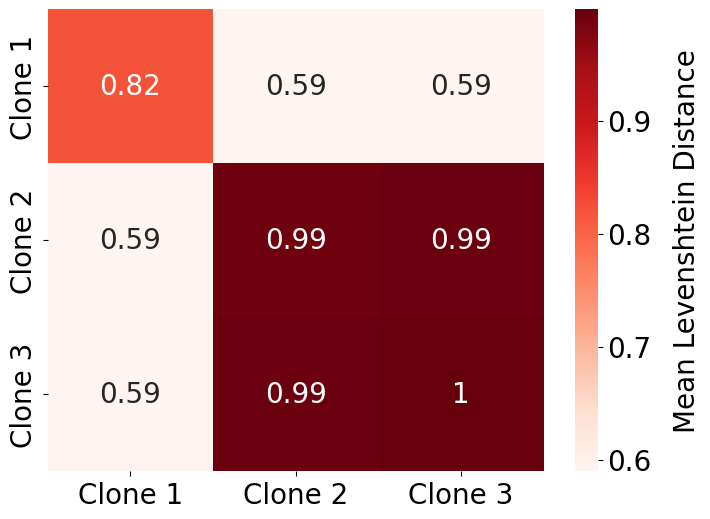

Processing column: full_aa_seq_filt_VDJ
Root - 0: 0.1178
Root - 1: 0.1023

========== Alignment against Root (Root) ==========

Root:    QLVLTQSPSASASLGASVKLTCTLSSGHSSYAIAWHQQQPEKGPRYLMKLNSDGSHSKGDGIPDRFSGSSSGAERYLTIS
0       : .V....L...................E..................F...V.G....N..A....................
1       : .V....L......................................F...V.G....N..A....................

Root:    SLQSEDEADYYCQTWGTGI--
0       : ..........L..S...YVVF
1       : ..........L..S...YVVF



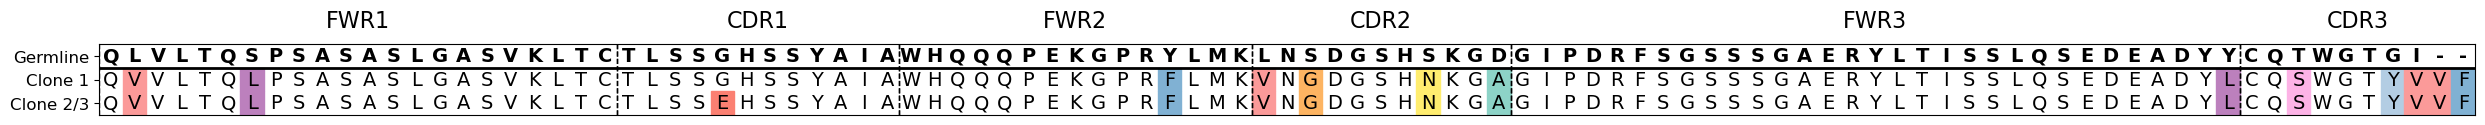

In [10]:
import warnings
warnings.filterwarnings('ignore')
import os
import numpy as np
import pandas as pd
import scanpy as sc
from Bio import SeqIO, Phylo
from Bio.Seq import Seq
from io import StringIO
from Bio import AlignIO
from Bio.SeqRecord import SeqRecord
from Bio.Align.Applications import ClustalwCommandline
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, fcluster, to_tree
from Bio.Phylo.Newick import Tree, Clade
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from matplotlib.patches import Patch, Rectangle
from matplotlib.colors import to_rgba
from scipy.stats import chi2_contingency
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist
import matplotlib.gridspec as gridspec
from sklearn.metrics import pairwise_distances
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import Levenshtein
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt
from scipy.spatial.distance import squareform
from Bio.Align import AlignInfo
from Bio.Phylo.TreeConstruction import DistanceCalculator


adata = sc.read_h5ad('../data/PCROWD_MM.h5ad')

mgip_col = f"Clone 1 (n=1,030)" #f"<0.2g/L (n={mgip_count:,})"
mgus_col = f"Clone 2 (n=8,712)" #f"≥0.2g/L (n={mgus_count:,})"
lc_col = f"Clone 3 (n=8,710)" #f"LC MS-MGUS (n={lc_count:,})"

adata.obs_names = adata.obs_names.str.split("-XXXX794").str[0]

lc_barcodes = adata.obs[adata.obs[lc_col] == lc_col].index.tolist()
mgip_barcodes = adata.obs[adata.obs[mgip_col] == mgip_col].index.tolist()
mgus_barcodes = adata.obs[adata.obs[mgus_col] == mgus_col].index.tolist()
normal_barcodes = adata.obs[adata.obs['tumor_id'] == 'N'].index.tolist()

clone_dict = dict(zip(adata.obs['barcode'], adata.obs['clone_opt']))

barcode_dict = {
    'lc': lc_barcodes,
    'mgip': mgip_barcodes,
    'mgus': mgus_barcodes,
    'normal': normal_barcodes
}

for name, interest_list in barcode_dict.items():
    print(name, len(interest_list))


vdj_df = pd.read_csv('../data/PCROWD_MM_BCR.csv', sep=",")
#vdj_df['barcode'] = vdj_df['Unnamed: 0']
#vdj_df['mz_ratio'] = vdj_df['est_mz_ratio']

valid_barcodes = set(adata.obs.index)
vdj_df_filtered = vdj_df[vdj_df['barcode'].isin(valid_barcodes)]

def categorize_barcode(barcode):
    if barcode in lc_barcodes:
        return 'Clone 3'#'LC MS-MGUS'
    elif barcode in mgip_barcodes:
        return 'Clone 1' #'<0.2g/L'
    elif barcode in mgus_barcodes:
        return 'Clone 2' #'≥0.2g/L'
    elif barcode in normal_barcodes:
        return 'normal'
    else:
        return 'unassigned tumor'

# Create new dataframe
new_df = vdj_df_filtered[['barcode', 'vdj_nt', 'full_aa_seq_filt', 'mz_ratio']].copy()
new_df['types'] = new_df['barcode'].apply(categorize_barcode)
new_df['clone_cnv'] = new_df['barcode'].map(clone_dict)

anchor = "GGGTKLTVL"

def extract_vdj_prefix(seq, anchor):
    if not isinstance(seq, str) or pd.isna(seq):
        return seq
    idx = seq.find(anchor)
    return seq[:idx] if idx != -1 else seq  

new_df['full_aa_seq_filt_VDJ'] = new_df['full_aa_seq_filt'].apply(lambda x: extract_vdj_prefix(x, anchor))

print(new_df.groupby('types').size())

seq_col = "vdj_nt"
#seq_col = "full_aa_seq_filt"


############################# Levenshtein
### add germline
germ_nt = "CAGCTTGTGCTGACTCAATCGCCCTCTGCCTCTGCCTCCCTGGGAGCCTCGGTCAAGCTCACCTGCACTCTGAGCAGTGGGCACAGCAGCTACGCCATCGCATGGCATCAGCAGCAGCCAGAGAAGGGCCCTCGGTACTTGATGAAGCTTAACAGTGATGGCAGCCACAGCAAGGGGGACGGGATCCCTGATCGCTTCTCAGGCTCCAGCTCTGGGGCTGAGCGCTACCTCACCATCTCCAGCCTCCAGTCTGAGGATGAGGCTGACTATTACTGTCAGACCTGGGGCACTGGCATT"
germ_aa = "QLVLTQSPSASASLGASVKLTCTLSSGHSSYAIAWHQQQPEKGPRYLMKLNSDGSHSKGDGIPDRFSGSSSGAERYLTISSLQSEDEADYYCQTWGTGI"

new_row = {
    'types': 'germline',
    'vdj_nt': germ_nt,  
    'full_aa_seq_filt_VDJ': germ_aa, 
    'barcode': 'GERMLINE_REF'  
}
new_df = pd.concat([new_df, pd.DataFrame([new_row])], ignore_index=True)





### assign col
seq_col = "vdj_nt"
#seq_col = "full_aa_seq_filt"
type_col = "types"

### change names
new_df['sample'] = new_df['barcode'].str.split("_1_").str[-1].str.split("_CD").str[0]

type_label_map = {
    "Clone 1"        : "MGIP Clone",
    "Clone 2"        : "MGUS Clone",
    "Clone 3"        : "LC-MGUS Clone",
    "germline"       : "Germline",
    "unassigned tumor": "Unassigned tumor",
    "normal"         : "Normal PC",
}
new_df["display_type"] = new_df[type_col].map(type_label_map).fillna(new_df[type_col])

# is_normal = new_df['types'] == 'normal'
# new_df.loc[is_normal & new_df['sample'].str.contains('PB', na=False), 'new_types'] = 'normal PC in PB'
# new_df.loc[is_normal & new_df['sample'].str.contains('BM', na=False), 'new_types'] = 'normal PC in BM'

TYPE_COLORS = {
    "MGIP Clone"      : "#E63946",
    "MGUS Clone"      : "#F4A261",
    "LC-MGUS Clone"   : "#2A9D8F",
    "Germline"        : "#333333",
    "Unassigned tumor": "#A8DADC",
    "Normal PC"       : "#457B9D",
}
DEFAULT_COLOR = "#AAAAAA"

type_col = 'new_types'

# Group sequences by types and calculate pairwise similarity mean per type
grouped_sequences = new_df.groupby("types")[seq_col].unique()

# Create mapping of types to their sequences
type_to_sequences = {group: list(sequences) for group, sequences in grouped_sequences.items()}
type_names = ['Clone 1', 'Clone 2', 'Clone 3', ] #list(type_to_sequences.keys())
num_types = len(type_names)

# Initialize similarity matrices for mean similarity calculations
levenshtein_matrix = np.zeros((num_types, num_types))
cosine_matrix = np.zeros((num_types, num_types))

# Get sequence counts per type for weighted similarity computation
seq_counts = new_df.groupby(["types", seq_col]).size().reset_index(name="count")

# Create a mapping of sequence counts
seq_count_dict = {(row["types"], row[seq_col]): row["count"] for _, row in seq_counts.iterrows()}

# Compute pairwise similarity mean per type group
for i, type1 in enumerate(type_names):
    for j, type2 in enumerate(type_names):
        if i <= j:  # Compute only once (symmetric matrix)
            seqs1 = type_to_sequences[type1]
            seqs2 = type_to_sequences[type2]

            # Compute Levenshtein distances
            lev_distances = np.array([
                [Levenshtein.distance(seq1, seq2) for seq2 in seqs2] for seq1 in seqs1
            ])
            lev_similarity = 1 - (lev_distances / np.max(lev_distances))

            # Weight similarity by sequence counts
            weight_matrix = np.array([
                [seq_count_dict.get((type1, seq1), 1) * seq_count_dict.get((type2, seq2), 1)
                 for seq2 in seqs2] for seq1 in seqs1
            ])
            weighted_lev_similarity = np.sum(lev_similarity * weight_matrix) / np.sum(weight_matrix)
            levenshtein_matrix[i, j] = levenshtein_matrix[j, i] = weighted_lev_similarity

            # Compute Cosine similarity
            all_sequences = seqs1 + seqs2
            vectorizer = CountVectorizer(analyzer="char", ngram_range=(1, 3))
            X_cosine = vectorizer.fit_transform(all_sequences)
            cosine_sim = 1 - pairwise_distances(X_cosine, metric="cosine")

            # Extract relevant similarity values
            cosine_values = cosine_sim[:len(seqs1), len(seqs1):].flatten()

            # Weight cosine similarity by sequence counts
            weighted_cosine_similarity = np.sum(cosine_values * weight_matrix.flatten()) / np.sum(weight_matrix)
            cosine_matrix[i, j] = cosine_matrix[j, i] = weighted_cosine_similarity

# Convert to DataFrame for visualization
levenshtein_df = pd.DataFrame(levenshtein_matrix, index=type_names, columns=type_names)
cosine_df = pd.DataFrame(cosine_matrix, index=type_names, columns=type_names)

# Plot heatmaps
plt.figure(figsize=(8, 6))
plt.rcParams.update({'font.size': 20})
#fig, axes = plt.subplots(1, 2, figsize=(18, 6))

ax = sns.heatmap(levenshtein_df, annot=True, cmap="Reds")  #, ax=axes[0])
#axes[0].set_title("Weighted Levenshtein Similarity (Mean per Type)")
#sns.heatmap(cosine_df, annot=True, cmap="coolwarm", ax=axes[1])
#axes[1].set_title("Weighted Cosine Similarity (Mean per Type)")

colorbar = ax.collections[0].colorbar  # Get the colorbar object
colorbar.set_label('Mean Levenshtein Distance', labelpad=15)  # Set label and labelpad

plt.savefig(f'../00.Figures/PANGEA_4385_VDJseq_Levenshtein.pdf', bbox_inches='tight')
plt.show()

############################# Visualize 
new_df['types'] = new_df['types'].astype(str)

# remove singletons (normals)
new_df = new_df[new_df.groupby('full_aa_seq_filt')['full_aa_seq_filt'].transform('size') > 100]
# remove unassigned tumors
new_df = new_df[new_df['types'] != 'unassigned tumor']

## Amino acid
root_sequence = "QLVLTQSPSASASLGASVKLTCTLSSGHSSYAIAWHQQQPEKGPRYLMKLNSDGSHSKGDGIPDRFSGSSSGAERYLTISSLQSEDEADYYCQTWGTGI"

clustalw_exe = "/usr/bin/clustalw" 

#for seq_col in ['vdj_nt', 'full_aa_seq_filt']:
#for seq_col in ['vdj_nt']:
for seq_col in ['full_aa_seq_filt_VDJ']:
    print(f"Processing column: {seq_col}")
    # Define unique file names per sequence column
    fasta_file = f"../data/sequences_{seq_col}.fasta"
    aligned_fasta = f"../data/sequences_{seq_col}.aln"
    tree_file = f"../data/sequences_{seq_col}.dnd"
    rooted_tree_file = f"../data/rooted_tree_{seq_col}.newick"

    # 1. Convert DataFrame to FASTA Format
    records = []
    # Add root sequence as a reference (Name germline as 'Root')
    records.append(SeqRecord(Seq(root_sequence), id="Root", description="Root Sequence"))

    # Create FASTA file for the current seq_col
    leaf_name_dict, mz_dict = {}, {}
    for i, seq in enumerate(new_df[seq_col].unique()):
        leaf_name_dict[str(i)] = new_df[new_df[seq_col] == seq]['types'].unique()
        mz_dict[str(i)] = new_df[new_df[seq_col] == seq]['mz_ratio'].unique()
        records.append(SeqRecord(Seq(seq), id=str(i)))

    SeqIO.write(records, fasta_file, "fasta")

    # 1. Run ClustalW for Multiple Sequence Alignment
    clustalw_cline = ClustalwCommandline(clustalw_exe, infile=fasta_file)
    stdout, stderr = clustalw_cline()

    # 2. Generate a Phylogenetic Tree (Unrooted)
    clustalw_cline_tree = ClustalwCommandline(clustalw_exe, infile=fasta_file, tree=True, outfile=tree_file)
    stdout, stderr = clustalw_cline_tree()

    # 3. Root the Tree using the Given Root Sequence
    tree = Phylo.read(tree_file, "newick")
    tree.root_with_outgroup("Root")  # Ensure the root is correctly named in your data (germline='Root')

    # Save the rooted tree
    Phylo.write(tree, rooted_tree_file, "newick")

    # 4. Load the Rooted Tree and Draw It
    tree = Phylo.read(rooted_tree_file, "newick")

    ##### Alignment Check #####
    # 1. Read aligned FASTA file
    alignment = AlignIO.read(aligned_fasta, "clustal")

    alignment = AlignIO.read(aligned_fasta, "clustal")
    calculator = DistanceCalculator('blosum62')
    dm = calculator.get_distance(alignment)

    for i in dm.names:
        if i == 'Root':
            for j in dm.names:
                if i != j:
                    print(f"{i} - {j}: {dm[i, j]:.4f}")


############### Print alignment
from Bio import AlignIO

# ClustalW read
alignment = AlignIO.read(aligned_fasta, "clustal")

# Root sequence 
root_seq = None
for record in alignment:
    if record.id == 'Root':
        root_seq = str(record.seq)
        break
assert root_seq is not None, "Root sequence not found in alignment!"

# Visualize alignment against Root
def visualize_alignment(alignment, root_id='Root', line_width=80):
    root_seq = None
    aligned_records = []
    for record in alignment:
        if record.id == root_id:
            root_seq = str(record.seq)
        else:
            aligned_records.append((record.id, str(record.seq)))

    assert root_seq is not None, "Root sequence not found!"

    print(f"\n{'='*10} Alignment against Root ({root_id}) {'='*10}\n")

    for start in range(0, len(root_seq), line_width):
        print(f"Root:    {root_seq[start:start+line_width]}")
        for rec_id, seq in aligned_records:
            aligned = ''
            for i in range(start, start+line_width):
                if i >= len(seq):
                    break
                if seq[i] == root_seq[i]:
                    aligned += '.'
                elif seq[i] == '-':
                    aligned += '-'
                else:
                    aligned += seq[i]
            print(f"{rec_id:8}: {aligned}")
        print()

visualize_alignment(alignment)
                    
                    
# 1. Define germline subregions
fwr1 = "QLVLTQSPSASASLGASVKLTC"
cdr1 = "TLSSGHSSYAIA"
fwr2 = "WHQQQPEKGPRYLMK"
cdr2 = "LNSDGSHSKGD"
fwr3 = "GIPDRFSGSSSGAERYLTISSLQSEDEADYY"
cdr3 = "CQTWGTGI"
germline_concat = fwr1 + cdr1 + fwr2 + cdr2 + fwr3 + cdr3

# 2. Load alignment
alignment = AlignIO.read("../data/sequences_full_aa_seq_filt_VDJ.aln", "clustal")
aligned_ids = [record.id for record in alignment]
aligned_seqs = [str(record.seq) for record in alignment]

n_seqs = len(aligned_seqs)
seq_len = len(aligned_seqs[0])

# 3. Map germline AAs to alignment positions
germline_aligned = aligned_seqs[aligned_ids.index('Root')]
aa_to_aln_index = []
aa_count = 0
for i, aa in enumerate(germline_aligned):
    if aa != '-':
        aa_to_aln_index.append(i)
        aa_count += 1
        if aa_count == len(germline_concat):
            break

# Get alignment indices for each region
def get_region_indices(start, region):
    region_len = len(region)
    return aa_to_aln_index[start], aa_to_aln_index[start + region_len - 1]

regions = {
    "FWR1": get_region_indices(0, fwr1),
    "CDR1": get_region_indices(len(fwr1), cdr1),
    "FWR2": get_region_indices(len(fwr1)+len(cdr1), fwr2),
    "CDR2": get_region_indices(len(fwr1)+len(cdr1)+len(fwr2), cdr2),
    "FWR3": get_region_indices(len(fwr1)+len(cdr1)+len(fwr2)+len(cdr2), fwr3),
    "CDR3": get_region_indices(len(fwr1)+len(cdr1)+len(fwr2)+len(cdr2)+len(fwr3), cdr3)
}

# 4. Color scheme
aa_colors = {
    'A': '#8dd3c7', 'C': '#ffffb3', 'D': '#bebada', 'E': '#fb8072',
    'F': '#80b1d3', 'G': '#fdb462', 'H': '#b3de69', 'I': '#fccde5',
    'K': '#d9d9d9', 'L': '#bc80bd', 'M': '#ccebc5', 'N': '#ffed6f',
    'P': '#bc80bd', 'Q': '#ffb3b3', 'R': '#b0e0e6', 'S': '#fdb3e6',
    'T': '#bebada', 'V': '#fb9a99', 'W': '#ccebc5', 'Y': '#b3cde3',
    '-': '#ffffff'
}
default_color = '#ffffff'

# 5. Plot
#plt.figure(figsize=(20, 8))
plt.rcParams.update({'font.size': 20})
fig, ax = plt.subplots(figsize=(seq_len * 0.25, n_seqs * 0.9)) 

root_seq = aligned_seqs[aligned_ids.index('Root')]

for i, (sid, row) in enumerate(zip(aligned_ids, aligned_seqs)):
    for j, aa in enumerate(row):
        if sid == 'Root':
            ax.text(j + 0.5, n_seqs - i - 0.5, aa, ha='center', va='center', fontsize=14, fontweight='bold')#color='black')
        else:
            if aa != root_seq[j]:  # Color if different from root
                color = aa_colors.get(aa.upper(), default_color)
                ax.add_patch(plt.Rectangle((j, n_seqs - i - 1), 1, 1, color=color))
            ax.text(j + 0.5, n_seqs - i - 0.5, aa, ha='center', va='center', fontsize=14) #, fontweight='bold')

# 6. Vertical lines and region labels
for label, (start, end) in regions.items():
    ax.axvline(x=start, color='black', linestyle='--', linewidth=1)
    if label == 'CDR3': ## 2 deletion
        #ax.axvline(x=end + 3, color='black', linestyle='--', linewidth=1)
        mid = (start + end + 3) / 2
    else:
        ax.axvline(x=end + 1, color='black', linestyle='--', linewidth=1)
        mid = (start + end + 1) / 2
    ax.text(mid, -0.5, label, ha='center', va='bottom', fontsize=16) #, fontweight='bold')

# 7. Horizontal line separating germline
germline_index = aligned_ids.index('Root')
ax.axhline(y=n_seqs - germline_index, color='black', linestyle='-', linewidth=2)

# 8. Axis setup
id_dict = {'Root': 'Germline', '0': 'Clone 2/3', '1': 'Clone 1'}
aligned_ids_updated = [id_dict.get(k, k) for k in aligned_ids]

ax.set_xlim(0, seq_len)
ax.set_ylim(0, n_seqs)
ax.set_xticks([])
ax.set_yticks(np.arange(0.5, n_seqs + 0.5))
ax.set_yticklabels(aligned_ids_updated[::-1], fontsize=12)
ax.set_aspect('equal')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f'../00.Figures/PCROWD_MM_lightchain_AAseq.pdf', bbox_inches='tight')
plt.show()



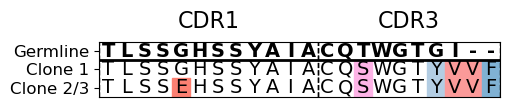

In [11]:
# 1. Define germline subregions
fwr1 = "QLVLTQSPSASASLGASVKLTC"
cdr1 = "TLSSGHSSYAIA"
fwr2 = "WHQQQPEKGPRYLMK"
cdr2 = "LNSDGSHSKGD"
fwr3 = "GIPDRFSGSSSGAERYLTISSLQSEDEADYY"
cdr3 = "CQTWGTGI"
germline_concat = fwr1 + cdr1 + fwr2 + cdr2 + fwr3 + cdr3

# 2. Load alignment
alignment = AlignIO.read("../data/sequences_full_aa_seq_filt_VDJ.aln", "clustal")
aligned_ids = [record.id for record in alignment]
aligned_seqs = [str(record.seq) for record in alignment]

n_seqs = len(aligned_seqs)
seq_len = len(aligned_seqs[0])

# 3. Map germline AAs to alignment positions
germline_aligned = aligned_seqs[aligned_ids.index('Root')]
aa_to_aln_index = []
aa_count = 0
for i, aa in enumerate(germline_aligned):
    if aa != '-':
        aa_to_aln_index.append(i)
        aa_count += 1
        if aa_count == len(germline_concat):
            break

def get_region_indices(start, region):
    region_len = len(region)
    return aa_to_aln_index[start], aa_to_aln_index[start + region_len - 1]

regions = {
    "FWR1": get_region_indices(0, fwr1),
    "CDR1": get_region_indices(len(fwr1), cdr1),
    "FWR2": get_region_indices(len(fwr1)+len(cdr1), fwr2),
    "CDR2": get_region_indices(len(fwr1)+len(cdr1)+len(fwr2), cdr2),
    "FWR3": get_region_indices(len(fwr1)+len(cdr1)+len(fwr2)+len(cdr2), fwr3),
    "CDR3": get_region_indices(len(fwr1)+len(cdr1)+len(fwr2)+len(cdr2)+len(fwr3), cdr3)
}

# 4. Color scheme
aa_colors = {
    'A': '#8dd3c7', 'C': '#ffffb3', 'D': '#bebada', 'E': '#fb8072',
    'F': '#80b1d3', 'G': '#fdb462', 'H': '#b3de69', 'I': '#fccde5',
    'K': '#d9d9d9', 'L': '#bc80bd', 'M': '#ccebc5', 'N': '#ffed6f',
    'P': '#bc80bd', 'Q': '#ffb3b3', 'R': '#b0e0e6', 'S': '#fdb3e6',
    'T': '#bebada', 'V': '#fb9a99', 'W': '#ccebc5', 'Y': '#b3cde3',
    '-': '#ffffff'
}
default_color = '#ffffff'

# 5. Extract ONLY CDR1 and CDR3 columns
cdr1_start, cdr1_end = regions['CDR1']
cdr3_start, cdr3_end = regions['CDR3']

display_columns = list(range(cdr1_start, cdr1_end + 1)) + list(range(cdr3_start, min(cdr3_end + 3, seq_len)))
new_seq_len = len(display_columns)

# Plot setup
plt.rcParams.update({'font.size': 20})
fig, ax = plt.subplots(figsize=(new_seq_len * 0.25, n_seqs * 0.9)) 

root_seq = aligned_seqs[aligned_ids.index('Root')]

for i, (sid, row) in enumerate(zip(aligned_ids, aligned_seqs)):
    for plot_x, j in enumerate(display_columns):
        aa = row[j]
        
        if sid == 'Root':
            ax.text(plot_x + 0.5, n_seqs - i - 0.5, aa, ha='center', va='center', fontsize=14, fontweight='bold')
        else:
            if aa != root_seq[j]:  
                color = aa_colors.get(aa.upper(), default_color)
                ax.add_patch(plt.Rectangle((plot_x, n_seqs - i - 1), 1, 1, color=color))
            ax.text(plot_x + 0.5, n_seqs - i - 0.5, aa, ha='center', va='center', fontsize=14)

# 6. Vertical lines and region labels
def get_new_x(orig_idx):
    return display_columns.index(orig_idx)

new_regions = {
    'CDR1': (get_new_x(cdr1_start), get_new_x(cdr1_end)),
    'CDR3': (get_new_x(cdr3_start), get_new_x(min(cdr3_end + 2, seq_len - 1)))
}

for label, (start, end) in new_regions.items():
    ax.axvline(x=start, color='black', linestyle='--', linewidth=1)
    ax.axvline(x=end + 1, color='black', linestyle='--', linewidth=1)
    mid = (start + end + 1) / 2
    ax.text(mid, -0.5, label, ha='center', va='bottom', fontsize=16)

# 7. Horizontal line separating germline
germline_index = aligned_ids.index('Root')
ax.axhline(y=n_seqs - germline_index, color='black', linestyle='-', linewidth=2)

# 8. Axis setup
id_dict = {'Root': 'Germline', '0': 'Clone 2/3', '1': 'Clone 1'}
aligned_ids_updated = [id_dict.get(k, k) for k in aligned_ids]

ax.set_xlim(0, new_seq_len)
ax.set_ylim(0, n_seqs)
ax.set_xticks([])
ax.set_yticks(np.arange(0.5, n_seqs + 0.5))
ax.set_yticklabels(aligned_ids_updated[::-1], fontsize=12)
ax.set_aspect('equal')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('../00.Figures/PCROWD_MM_lightchain_AAseq_CDR1_CDR3.pdf', bbox_inches='tight')
plt.show()

# 05. CNV probability matrix visualization

,11:11b(amp),20:20a(del),9:9c(amp),13:13a(del)
MS_group_v2,,,,
Clone 1,0.635260,0.376179,0.337489,0.077961
Clone 2,0.701780,0.508113,0.465918,0.131747
Clone 3,0.909553,0.814418,0.777453,0.448493


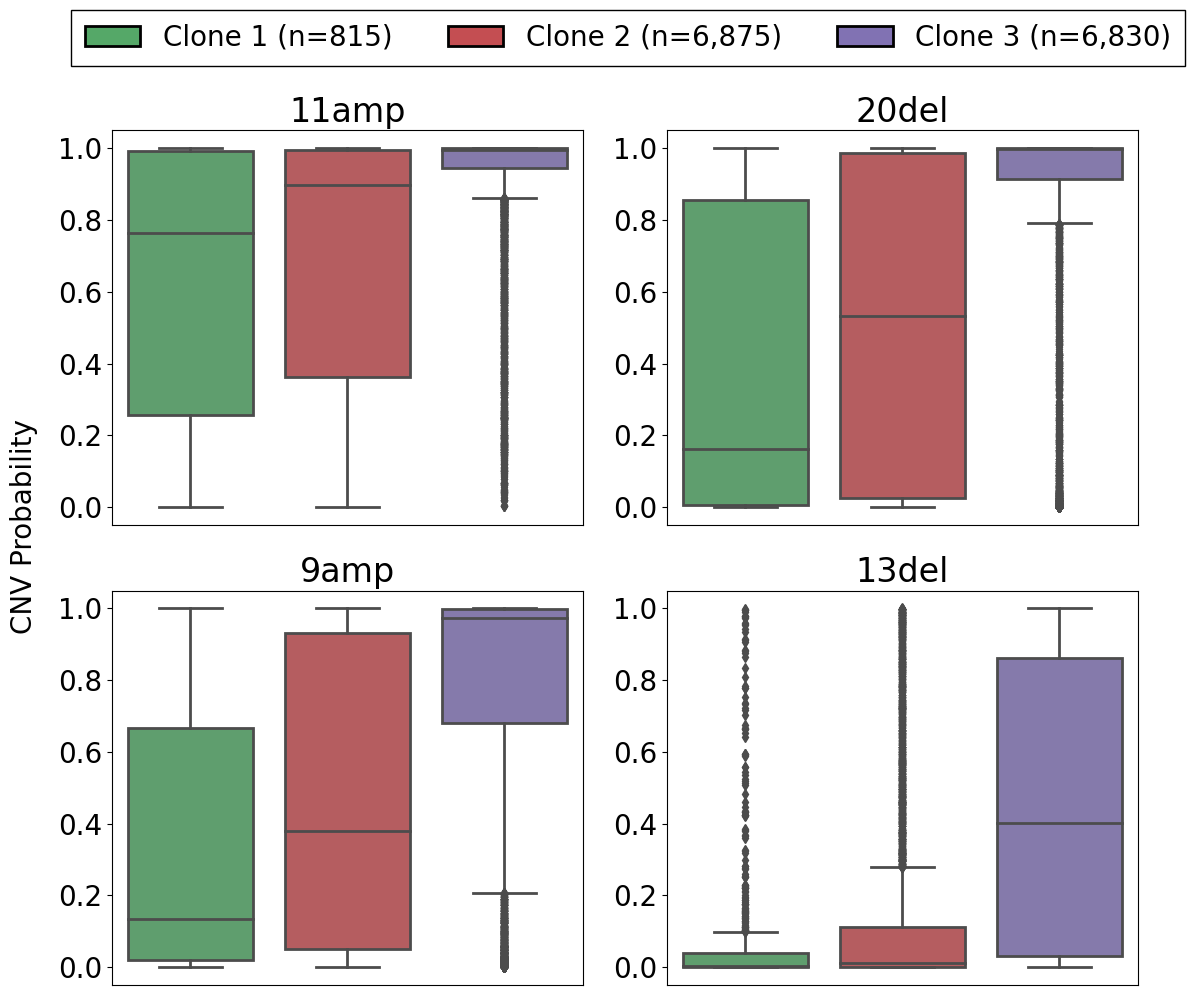

In [9]:
import warnings
warnings.filterwarnings('ignore')
import os
import numpy as np
import pandas as pd
import scanpy as sc
from Bio import SeqIO, Phylo
from Bio.Seq import Seq
from io import StringIO
from Bio import AlignIO
from Bio.SeqRecord import SeqRecord
from Bio.Align.Applications import ClustalwCommandline
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, fcluster, to_tree
from Bio.Phylo.Newick import Tree, Clade
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from matplotlib.patches import Patch, Rectangle
from matplotlib.colors import to_rgba
from scipy.stats import chi2_contingency
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist
import matplotlib.gridspec as gridspec

adata = sc.read_h5ad('../data/PCROWD_MM.h5ad')

## Load data
numbat_joint_df = pd.read_csv(f'../data/PCROWD_MM_joint_post_2.tsv', sep="\t", index_col='cell')
numbat_seg_df = pd.read_csv(f'../data/PCROWD_MM_segs_consensus_2.tsv', sep="\t")
numbat_clone_df = pd.read_csv(f'../data/PCROWD_MM_clone_post_2.tsv', sep="\t", index_col='cell')


## Create cell X CNV prob matrix (per CNV type)
numbat_joint_df['segment_id'] = numbat_joint_df['CHROM'].astype(str) + ':' + numbat_joint_df['seg_label'].astype(str)

# pivot: rows = cell, columns = segment, values = p_cnv
cnv_matrix = numbat_joint_df.pivot_table(
    index='cell', 
    columns='segment_id', 
    values='p_cnv',
    aggfunc='mean',  
    fill_value=0    
)

#prinit(cnv_matrix)

# Join
sc_data = adata.obs.join(cnv_matrix, how='left')
# Drop non-cnv informative cells
sc_data = sc_data.dropna(subset=cnv_matrix.columns)

# CNV columns and simplified labels
cnv_cols = ['11:11b(amp)', '20:20a(del)', '9:9c(amp)', '13:13a(del)']
label_map = {
    '11:11b(amp)': '11amp',
    '20:20a(del)': '20del',
    '9:9c(amp)': '9amp',
    '13:13a(del)': '13del'
}

ms_order = ['Clone 1', 'Clone 2', 'Clone 3']
subset_data = sc_data[sc_data['MS_group_v2'].isin(ms_order)].copy()
subset_data['MS_group_v2'] = pd.Categorical(subset_data['MS_group_v2'], categories=ms_order, ordered=True)

# Matrix
cnv_mean_matrix = subset_data.groupby('MS_group_v2')[cnv_cols].mean()
display(cnv_mean_matrix)

# Plot
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
plt.rcParams.update({'font.size': 20})
axes = axes.flatten()

colors = sns.color_palette("deep", n_colors=5)
color_map = {
    'Clone 1': colors[2],
    'Clone 2': colors[3],
    'Clone 3': colors[4],
}

# Clone count
clone_counts = subset_data['MS_group_v2'].value_counts().to_dict()

for i, col in enumerate(cnv_cols):
    sns.boxplot(
        data=subset_data,
        x='MS_group_v2',
        y=col,
        ax=axes[i],
        palette=color_map,
        linewidth=2,
    )
    
    
    axes[i].set_title(f'{label_map[col]}')
    axes[i].set_xlabel("")  
    axes[i].set_ylabel("") 
    axes[i].set_xticks([]) 


#fig.text(0.54, 0.035, 'MS Group', ha='center', fontsize=16)
fig.text(0.035, 0.54, 'CNV Probability', va='center', rotation='vertical')


legend_elements = []
for clone in ['Clone 1', 'Clone 2', 'Clone 3']:
    count = clone_counts.get(clone, 0)
    label = f'{clone} (n={count:,})'
    patch = Patch(
        facecolor=color_map[clone],
        edgecolor='black',    
        linewidth=2,     
        label=label
    )
    legend_elements.append(patch)

fig.legend(
    handles=legend_elements, 
    loc='upper center', 
    bbox_to_anchor=(0.55, 1.07), 
    ncol=3, 
    fontsize=20,
    frameon=True,                
    edgecolor='black',        
    framealpha=1.0,            
    borderpad=0.5,             
    fancybox=False             
)


plt.tight_layout(rect=[0.05, 0.05, 1, 1])
plt.savefig('../00.Figures/PCROWD_MM_CNVprob_boxplots.pdf', format='pdf', bbox_inches='tight')
plt.show()




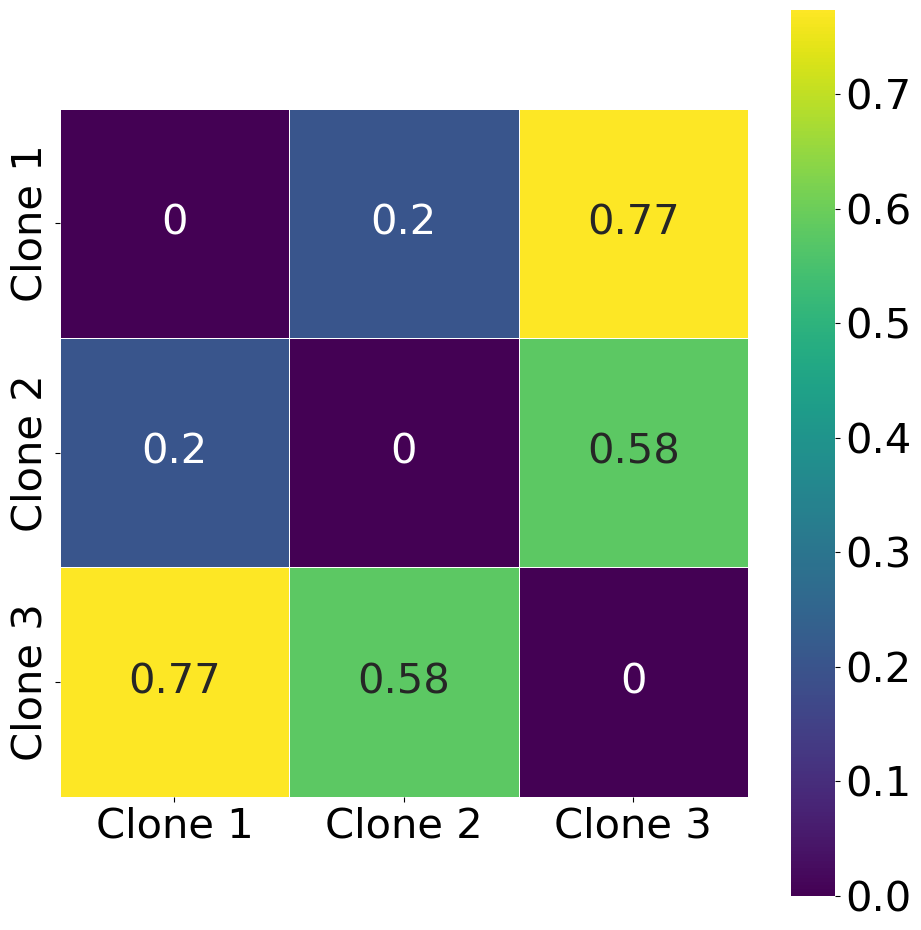

In [10]:
from scipy.spatial.distance import pdist, squareform
import seaborn as sns
import matplotlib.pyplot as plt

cnv_cols = [
    '11:11b(amp)',
    '20:20a(del)',
    '9:9c(amp)',
    '13:13a(del)'
            ]

#cnv_only = sc_data[cnv_matrix.columns]
cnv_only = sc_data[cnv_cols]

group_mean_matrix = cnv_only.groupby(sc_data['MS_group_v2']).mean()

ordered_groups = ['Clone 1', 'Clone 2', 'Clone 3']

group_mean_matrix_ordered = group_mean_matrix.loc[ordered_groups]

dist_mat_ordered = pd.DataFrame(
    squareform(pdist(group_mean_matrix_ordered, metric='euclidean')),
    index=ordered_groups,
    columns=ordered_groups
)

plt.figure(figsize=(10, 10))
plt.rcParams.update({'font.size': 30})
sns.heatmap(dist_mat_ordered, annot=True, cmap='viridis', square=True, 
            cbar=True, linewidths=0.5)
plt.tight_layout()
plt.savefig(f'../00.Figures/PCROWD_MM_CNVprob_Euclidean_heatmap.pdf', format='pdf', bbox_inches='tight')
plt.show()




# 06. Schematic diagram

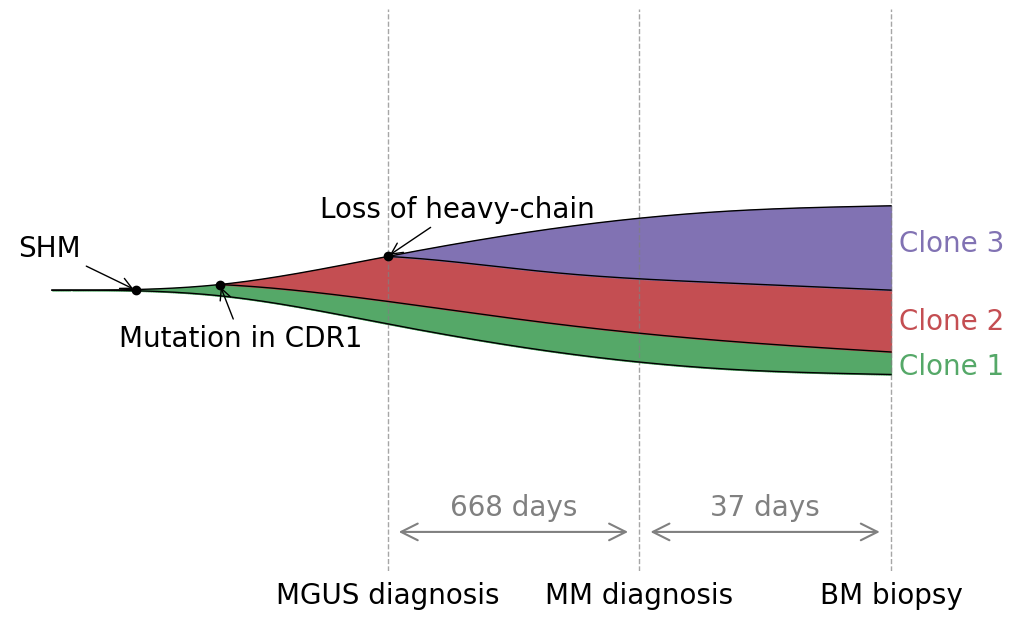

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.interpolate import make_interp_spline

def create_smooth_curve(x_base, y_base, x_smooth):
    x_base = np.array(x_base)
    y_base = np.array(y_base)
    k = min(3, len(x_base) - 1)

    spline = make_interp_spline(x_base, y_base, k=k, bc_type='natural')
    return spline(x_smooth)


x_base = np.array([0, 1, 2, 3, 4, 5])
x_smooth = np.linspace(x_base.min(), x_base.max(), 500)

# 1. Upper & lower outer bounds
y_upper_base = np.array([0.0, 0.01, 0.06, 0.11, 0.14, 0.15])
y_upper = create_smooth_curve(x_base, y_upper_base, x_smooth)
y_lower = -y_upper

# 2. Clone #2 defining lineage x=1~5 
y_red = np.array([0.01, 0.01, -0.02, -0.06, -0.09, -0.11])
red_lineage_line = create_smooth_curve(x_base, y_red, x_smooth)

# 3. Clone #3 (purple): x=2~5 
y_purple = np.array([0.06, 0.06, 0.06, 0.031, 0.013, 0.0])
purple_lineage_line = create_smooth_curve(x_base, y_purple, x_smooth)

# Draw chart
fig, ax = plt.subplots(figsize=(10, 6))
colors = sns.color_palette("deep", n_colors=5)
color_map = {
    'Clone 1': colors[2],
    'Clone 2': colors[3],
    'Clone 3': colors[4],
}


for i in range(len(x_smooth) - 1): 
#for i in range(20,21):
    xs = [x_smooth[i], x_smooth[i + 1]]
    yl = [y_lower[i], y_lower[i + 1]]
    yu = [y_upper[i], y_upper[i + 1]]
    yr = [red_lineage_line[i], red_lineage_line[i + 1]]
    yp = [purple_lineage_line[i], purple_lineage_line[i + 1]]
    
    if 0<= x_smooth[i] < 1: ## first part
        ax.fill_between(xs, yl, yu, color=color_map['Clone 1'])
    
    elif 1 <= x_smooth[i] < 2:
        ax.fill_between(xs, yl, yr, color=color_map['Clone 1'])
        ax.fill_between(xs, yr, yu, color=color_map['Clone 2'])

    elif 2 <= x_smooth[i] < 5:
        ax.fill_between(xs, yl, yr, color=color_map['Clone 1'])
        ax.fill_between(xs, yr, yp, color=color_map['Clone 2'])
        ax.fill_between(xs, yp, yu, color=color_map['Clone 3'])


ax.plot(x_smooth, y_upper, color='black', linewidth=1)
ax.plot(x_smooth, y_lower, color='black', linewidth=1)
ax.plot(x_smooth[100:], red_lineage_line[100:], color='black', linewidth=1)
ax.plot(x_smooth[200:], purple_lineage_line[200:], color='black', linewidth=1)

# Show axis
ax.grid(True, linestyle='--', alpha=0.3)
ax.set_xlabel("Timepoint", fontsize=12)
ax.set_ylabel("Relative Value", fontsize=12)

ax.set_ylim(-0.5, 0.5)  # Set limits from -1 to 1

# Annotation
ax.plot(0.5, 0.0, 'o', color='black')  # Dot
ax.annotate("SHM", xy=(0.5, 0.0), xytext=(-0.2, 0.06),
             arrowprops=dict(arrowstyle="->"), fontsize=20)

ax.plot(1, 0.01, 'o', color='black')  # Dot
ax.annotate("Mutation in CDR1", xy=(1, 0.01), xytext=(0.4, -0.1),
             arrowprops=dict(arrowstyle="->"), fontsize=20)

ax.plot(2, 0.06, 'o', color='black')
ax.annotate("Loss of heavy-chain", xy=(2, 0.06), xytext=(1.6, 0.13),
             arrowprops=dict(arrowstyle="->"), fontsize=20)

# Clone annotation
ax.text(5.05, -0.15, "Clone 1", color = color_map['Clone 1'], fontsize=20)
ax.text(5.05, -0.07, "Clone 2", color = color_map['Clone 2'], fontsize=20)
ax.text(5.05, 0.07, "Clone 3", color = color_map['Clone 3'], fontsize=20)

#ax.axis('off')

# 2. x-label custom
#xticks = [0.5, 2, 3.5, 5]
xticks = [2, 3.5, 5]
xtick_labels = [
    "MGUS diagnosis", #"11/01/2019\nMGUS diagnosis", 
    "MM diagnosis", #"08/30/2021\nMM diagnosis", 
    "BM biopsy",#"10/06/2021\nBM biopsy"
]
ax.set_xticks(xticks)
ax.set_xticklabels(xtick_labels, fontsize=20)


table_df = pd.DataFrame({
    "11/01/2019": ["0.2g/dL", "IgA Lambda", "NA", "NA"],
    "08/30/2021": ["Not quantifiable", "IgA Lambda", "0.01 (High Lambda)", "NA"],
    "10/06/2021": ["Not quantifiable", "IgA Lambda", "0.01 (High Lambda)", 
                   "IgA Lambda (0.58g/L)\n& IgA (0.068g/L)"],
}, index=["SPEP", "IFX", "FLC", "MS"])

## Add days
date_dict = {
    "11/01/2019": pd.to_datetime("2019-11-01"),
    "08/30/2021": pd.to_datetime("2021-08-30"),
    "10/06/2021": pd.to_datetime("2021-10-06")
}

days_1 = (date_dict["08/30/2021"] - date_dict["11/01/2019"]).days
days_2 = (date_dict["10/06/2021"] - date_dict["08/30/2021"]).days

ax.annotate(
    "", xy=(3.45, -0.43), xytext=(2.05, -0.43),
    arrowprops=dict(arrowstyle="<->", color='gray', linewidth=1.5)
)
ax.text(2.75, -0.36, f"{days_1} days", ha='center', va='top', fontsize=20, color='gray')

ax.annotate(
    "", xy=(4.95, -0.43), xytext=(3.55, -0.43),
    arrowprops=dict(arrowstyle="<->", color='gray', linewidth=1.5)
)
ax.text(4.25, -0.36, f"{days_2} days", ha='center', va='top', fontsize=20, color='gray')

# Remove plot spline, tick, labels
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(left=False, right=False, top=False, bottom=False)
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
#ax.grid(False)
ax.grid(True, linestyle='--', linewidth=1, alpha=0.7, color='gray')

fig.tight_layout(pad=0)
plt.savefig('../00.Figures/PANGEA_4385_hypothetical_schematic_diagram.pdf', format='pdf', bbox_inches='tight')
plt.show()